# CoralNet deduplication review

Visual check of what `mermaidseg.datasets.coralnet.dedup.dedup` did to duplicated images: which copy was kept, which
points were **added** from other copies (union of annotations), which labels were **replaced**, and where
the copies' labels **contradict**.

For each image you get:
1. **Explanation**: the kept copy and why it was chosen, and what happened to its points.
2. **Copies table**: every byte-identical copy with its source, new split, conflict cluster and rank.
3. **Overview figure**: on the left, the merged annotations, coloured by status. Every changed point is numbered.
   On the right, the kept copy plus the copies that differ most, each with its own points:
   grey = the final label, blue = adds a point the kept copy lacks, orange = overruled.
4. **Crops** at full resolution: up to 5 random points of each status, including **unchanged original points**
   for comparison. Cropped unchanged points are ringed and numbered in the figure and listed in the table.
   The caption lists every distinct label with its count and sources; `→` marks the label that was used.
5. **Point table** with the same numbers (all changed points plus the cropped originals), final label, the copy it came from, the kept copy's original label
   and every copy's label.

**Point statuses**

| status | meaning |
|---|---|
| unchanged | kept copy had the point; all copies agree |
| added | kept copy had no point here; taken from another copy |
| replaced: finer | kept copy's label replaced by a finer, consistent one (e.g. hard coral → acropora) |
| replaced: compatible | labels don't clash, none covers the other (e.g. taxon vs condition); label with most taxonomic ranks used |
| replaced: unmapped label | kept copy's label is not in `class_to_concepts.csv`; another copy's mapped label used |
| kept over alternative | kept copy's label stayed; another copy had a coarser / synonym / compatible / unmapped label |
| contradictory | labels clash; best-ranked copy's label used |
| unknown | only unmapped labels; best-ranked copy's label used |

**Noting decisions**: refer to an image as `kept_source_id/kept_image_id` (shown in the explanation), and to a
point by its `nr` or by `(row, col)`. Numbers stay the same as long as the dedup outputs don't change.
`(row, col)` is the safer reference.

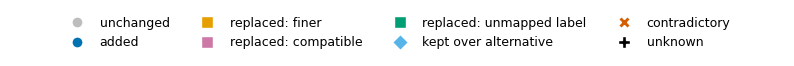

In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

import pandas as pd

from mermaidseg.datasets.coralnet.dedup.review import STATUSES, DedupReview, legend_figure

pd.set_option("display.max_colwidth", 120)
r = DedupReview()  # ~10 s
legend_figure();

## Overview

How many merged points have each status, and in how many duplicated images it occurs.
`r.images` has one row per duplicated image, with these counts, the kept copy and its new split. Filter it directly
if `select` doesn't cover what you need.

In [2]:
overview = pd.DataFrame({
    "points": r.prov["status"].value_counts().reindex(STATUSES),
    "images": (r.images[STATUSES] > 0).sum(),
})
display(overview)
print(f"{len(r.images):,} duplicated images, {r.images['overridden'].sum():,} with overridden annotations")
r.images.sort_values("n_changed", ascending=False).head(5)

,points,images
unchanged,1414537,50150
added,264320,6609
replaced: finer,5777,1561
replaced: compatible,3557,648
replaced: unmapped label,25600,579
kept over alternative,115975,7302
contradictory,50221,4978
unknown,808,120


50,841 duplicated images, 9,329 with overridden annotations


,kept_source_id,kept_image_id,overridden,n_copies,sources,n_points,unchanged,added,replaced: finer,replaced: compatible,replaced: unmapped label,kept over alternative,contradictory,unknown,split,n_changed
hash,,,,,,,,,,,,,,,,
cce92fb02550e1bc3262d832c38eeb3e,4759,4000478,True,4,[4759],4000,1000,3000,0,0,0,0,0,0,val,3000
f2e9d2518327632103c8368901ddcad0,4759,4000476,True,4,[4759],3999,999,2999,0,0,0,0,1,0,val,3000
745989df627c072d9a3cfb96d958c8dd,4759,4000480,True,4,[4759],3999,1000,2999,0,0,0,0,0,0,val,2999
8cacf37a7435542f187127b8d0e78382,4759,4000596,True,4,[4759],3997,999,2998,0,0,0,0,0,0,val,2998
b51aff276a31d73e3fedc24bca53ce96,4759,4000488,True,4,[4759],3998,1000,2998,0,0,0,0,0,0,val,2998


## Picking images

`r.select(...)` returns rows of `r.images`; `r.show_many(selection)` renders them. `r.show(hash)` renders one image.

- `status="contradictory"` (or a list) with `min_count=…`: images with at least that many points of the status
- `sources=[4710, 4721]`: images any of whose copies come from these sources
- `split="val"`: kept copy's split in the new config
- `image_ids=[...]`: look up specific CoralNet image ids (any copy)
- `order="random"` (with `seed`) or `order="most"` (most points of that status first)
- `show` options (output is kept small on purpose): `max_rows=15` (point-table rows, `None` for all),
  `max_copies=6`, `dpi=72` (figure resolution; raise it to zoom in on one image), `per_status=5` (crops per status), `crop_statuses=["contradictory", "unchanged"]`,
  `seed` (which points get cropped), `crops=False`, `table=False`, `all_points=True` (unchanged points in the table too),
  `max_copy_panels=4`; crop size via `r.plot_crops(*r.image_points(h), crop_px=…)`

## 1. Added points (union of annotations)

The kept copy lacked these points, so they come from another copy. In the figure they're blue. In the copy panels,
blue marks the copy that contributed each point.

---
### Image `50b45ff0c9da`
**Kept copy: 4596/3938809** (rare arrecifes 2023; new split: val), one of 2 byte-identical copies in 1 source(s).
Why this copy: duplicate within one source: kept the copy with more points / lower image id.
Merged result: 20 points (10 from the kept copy, 10 added from other copies).
- **added** (10): points only another copy had, added as is
Annotations for this image are **overridden** in the dataset.

,kept,source,image_id,name,new_split,cluster,source_rank,n_points,points_at_merged_locs
copy,,,,,,,,,
0,True,4596,3938809,rare arrecifes 2023,val,<NA>,<NA>,10,10
1,False,4596,3938852,rare arrecifes 2023,val,<NA>,<NA>,10,10


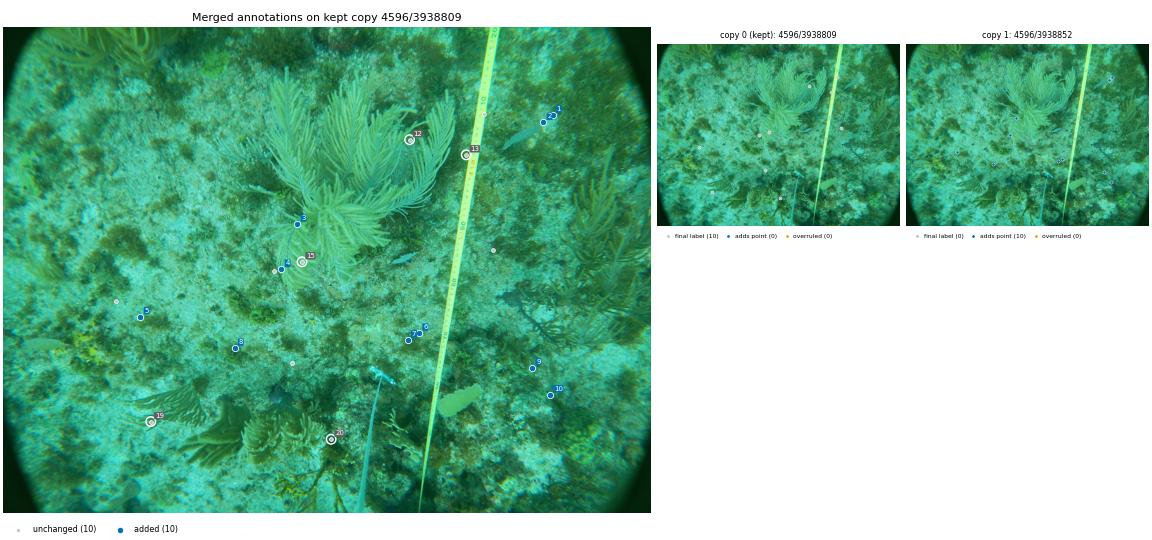

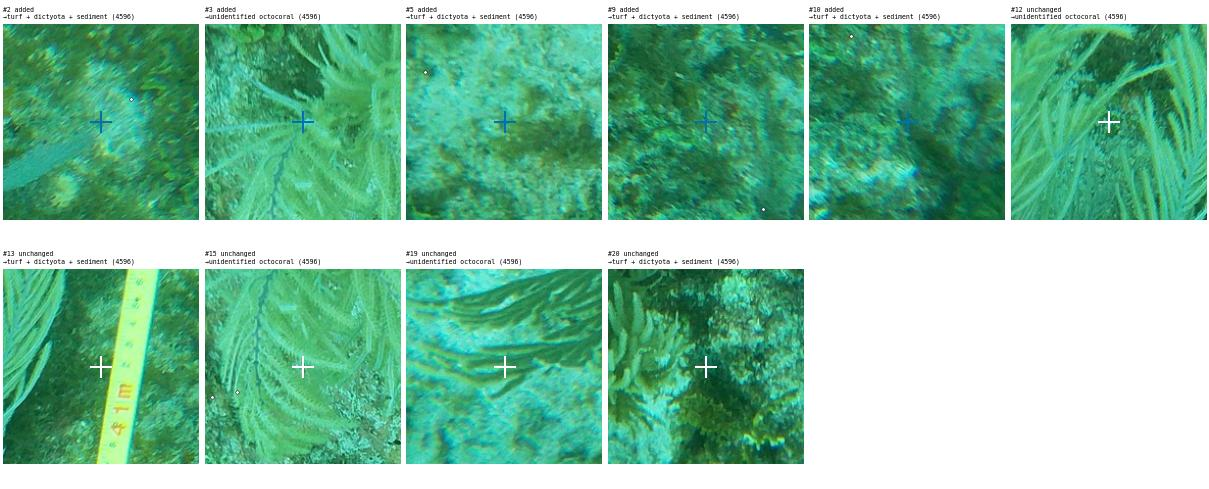

,status,row,col,final_label,from,kept_copy_label,labels_by_copy
nr,,,,,,,
2,added,300,1707,turf + dictyota + sediment,4596/3938852,—,→turf + dictyota + sediment (4596)
3,added,622,929,unidentified octocoral,4596/3938852,—,→unidentified octocoral (4596)
5,added,914,433,turf + dictyota + sediment,4596/3938852,—,→turf + dictyota + sediment (4596)
9,added,1076,1671,turf + dictyota + sediment,4596/3938852,—,→turf + dictyota + sediment (4596)
10,added,1161,1727,turf + dictyota + sediment,4596/3938852,—,→turf + dictyota + sediment (4596)
12,unchanged,355,1284,unidentified octocoral,4596/3938809,unidentified octocoral,→unidentified octocoral (4596)
13,unchanged,403,1463,turf + dictyota + sediment,4596/3938809,turf + dictyota + sediment,→turf + dictyota + sediment (4596)
15,unchanged,741,944,unidentified octocoral,4596/3938809,unidentified octocoral,→unidentified octocoral (4596)
19,unchanged,1246,466,unidentified octocoral,4596/3938809,unidentified octocoral,→unidentified octocoral (4596)


---
### Image `10aa70424c5a`
**Kept copy: 6618/5416090** (EACOP-TMRS-ULENGE; new split: train), one of 2 byte-identical copies in 1 source(s).
Why this copy: duplicate within one source: kept the copy with more points / lower image id.
Merged result: 50 points (25 from the kept copy, 25 added from other copies).
- **added** (25): points only another copy had, added as is
Annotations for this image are **overridden** in the dataset.

,kept,source,image_id,name,new_split,cluster,source_rank,n_points,points_at_merged_locs
copy,,,,,,,,,
0,True,6618,5416090,EACOP-TMRS-ULENGE,train,<NA>,<NA>,25,25
1,False,6618,5416184,EACOP-TMRS-ULENGE,train,<NA>,<NA>,25,25


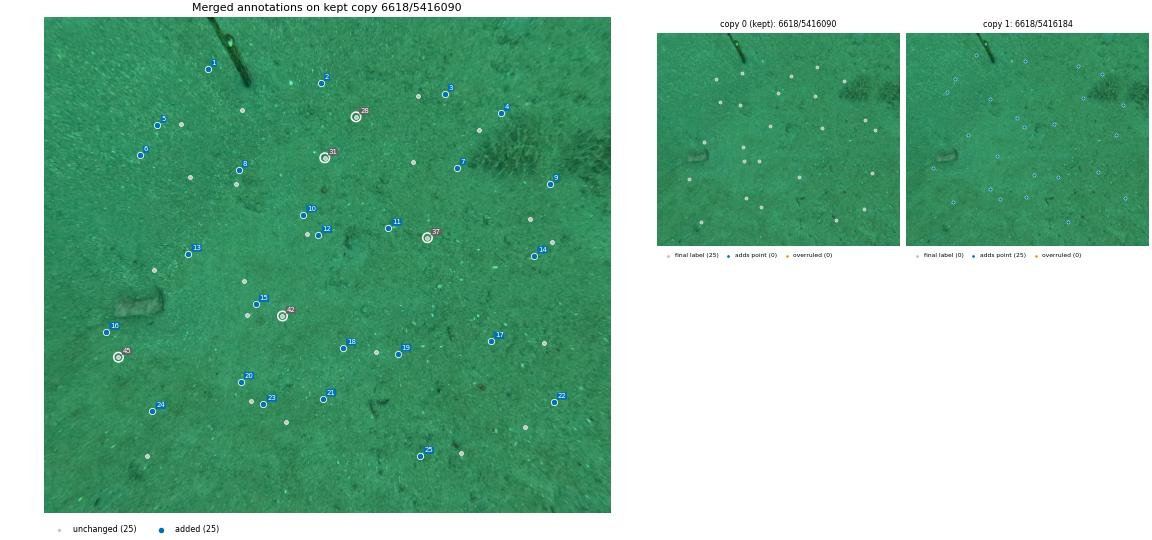

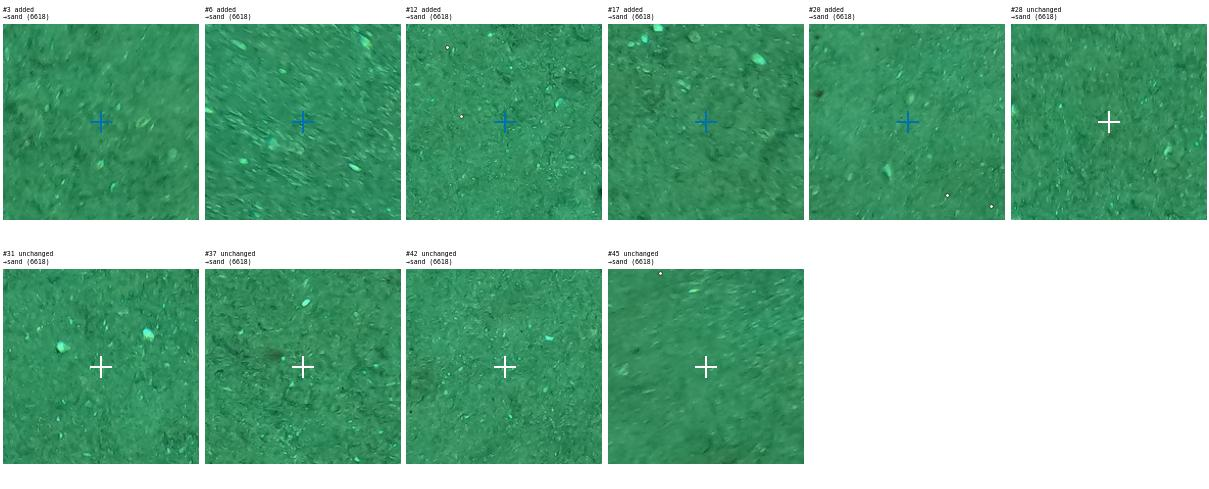

,status,row,col,final_label,from,kept_copy_label,labels_by_copy
nr,,,,,,,
3,added,276,1448,sand,6618/5416184,—,→sand (6618)
6,added,499,346,sand,6618/5416184,—,→sand (6618)
12,added,788,992,sand,6618/5416184,—,→sand (6618)
17,added,1172,1615,sand,6618/5416184,—,→sand (6618)
20,added,1317,711,sand,6618/5416184,—,→sand (6618)
28,unchanged,360,1128,sand,6618/5416090,sand,→sand (6618)
31,unchanged,508,1015,sand,6618/5416090,sand,→sand (6618)
37,unchanged,797,1386,sand,6618/5416090,sand,→sand (6618)
42,unchanged,1080,862,sand,6618/5416090,sand,→sand (6618)


… 15 more points: r.show('10aa70424c5a17179e89574ae81b8d42', max_rows=None) for all


In [3]:
r.show_many(r.select("added", n=2, seed=0))

## 2. Replaced by a finer label

The kept copy's label was replaced by a consistent, more specific label from another copy.

---
### Image `34370f121eb3`
**Kept copy: 4721/4095746** (Thuwal Bleaching Conditions; new split: train), one of 2 byte-identical copies in 2 source(s).
Why this copy: best-ranked source in conflict cluster 7 (rank 1 vs 4710's rank 2).
Merged result: 50 points (50 from the kept copy, 0 added from other copies).
- **replaced: finer** (5): kept copy's label replaced by a finer, consistent label
Annotations for this image are **overridden** in the dataset.

,kept,source,image_id,name,new_split,cluster,source_rank,n_points,points_at_merged_locs
copy,,,,,,,,,
0,True,4721,4095746,Thuwal Bleaching Conditions,train,7,1,50,50
1,False,4710,4030827,Thuwal Bleaching Taxonomic,train,7,2,50,50


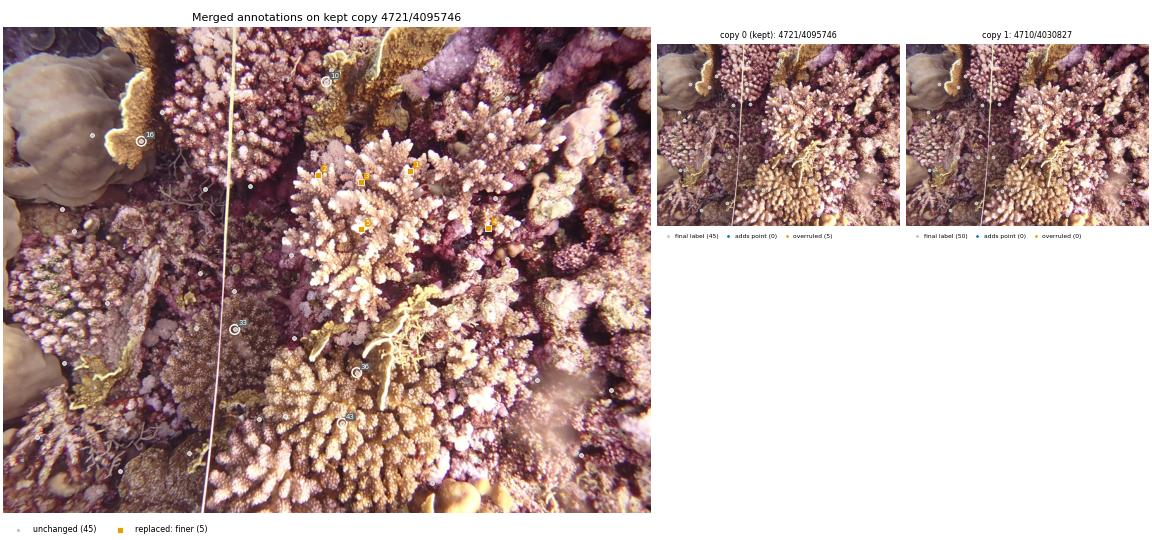

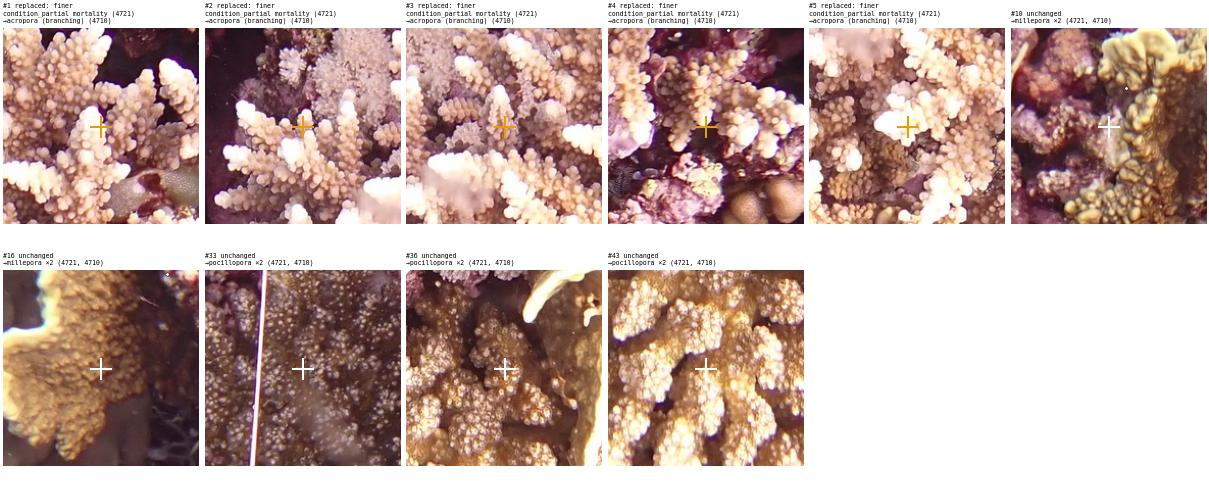

,status,row,col,final_label,from,kept_copy_label,labels_by_copy
nr,,,,,,,
1,replaced: finer,454,1286,acropora (branching),4710/4030827,condition_partial mortality,condition_partial mortality (4721) | →acropora (branching) (4710)
2,replaced: finer,466,995,acropora (branching),4710/4030827,condition_partial mortality,condition_partial mortality (4721) | →acropora (branching) (4710)
3,replaced: finer,490,1129,acropora (branching),4710/4030827,condition_partial mortality,condition_partial mortality (4721) | →acropora (branching) (4710)
4,replaced: finer,633,1533,acropora (branching),4710/4030827,condition_partial mortality,condition_partial mortality (4721) | →acropora (branching) (4710)
5,replaced: finer,637,1132,acropora (branching),4710/4030827,condition_partial mortality,condition_partial mortality (4721) | →acropora (branching) (4710)
10,unchanged,172,1021,millepora,4721/4095746,millepora,"→millepora ×2 (4721, 4710)"
16,unchanged,360,436,millepora,4721/4095746,millepora,"→millepora ×2 (4721, 4710)"
33,unchanged,955,731,pocillopora,4721/4095746,pocillopora,"→pocillopora ×2 (4721, 4710)"
36,unchanged,1091,1117,pocillopora,4721/4095746,pocillopora,"→pocillopora ×2 (4721, 4710)"


---
### Image `aa6f3ccf0bf0`
**Kept copy: 7569/5827597** (private/deleted source; new split: train), one of 14 byte-identical copies in 14 source(s).
Why this copy: best-ranked source in conflict cluster 0 (rank 1 vs 7568's rank 2).
Merged result: 50 points (50 from the kept copy, 0 added from other copies).
- **replaced: finer** (1): kept copy's label replaced by a finer, consistent label
- **kept over alternative** (49): kept copy's label stayed; another copy had a coarser/synonym/unmapped label
Annotations for this image are **overridden** in the dataset.

,kept,source,image_id,name,new_split,cluster,source_rank,n_points,points_at_merged_locs
copy,,,,,,,,,
0,True,7569,5827597,(private/deleted),train,0,1,50,50
1,False,7568,5827596,(private/deleted),train,0,2,50,50
2,False,6924,5526342,(private/deleted),train,0,3,50,50
3,False,6855,5487606,(private/deleted),train,0,7,50,50
4,False,7541,5810405,(private/deleted),train,0,22,50,50
5,False,7540,5810404,(private/deleted),train,0,23,50,50


… 8 more copies (max_copies=None to show all)


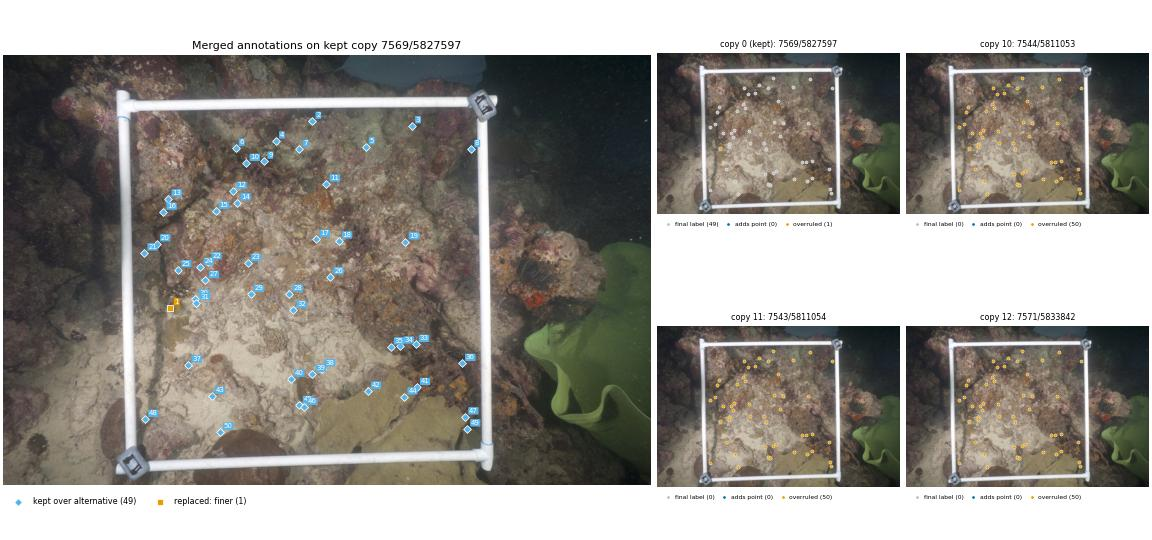

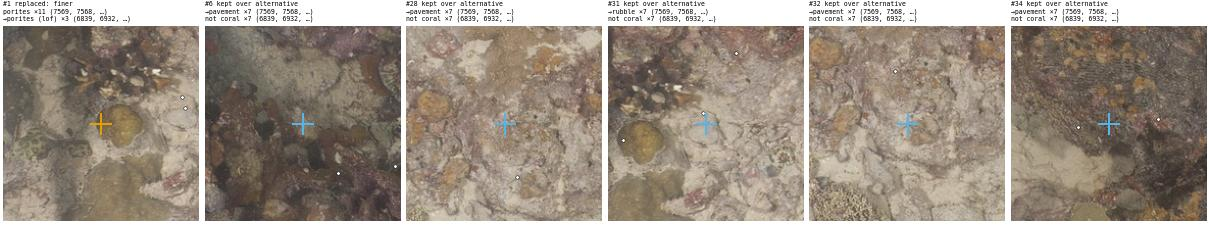

,status,row,col,final_label,from,kept_copy_label,labels_by_copy
nr,,,,,,,
1,replaced: finer,799,528,porites (lof),6839/5477376,porites,"porites ×11 (7569, 7568, 6924, 6855, …) | →porites (lof) ×3 (6839, 6932, 6868)"
6,kept over alternative,295,734,pavement,7569/5827597,pavement,"→pavement ×7 (7569, 7568, 6924, 6855, …) | not coral ×7 (6839, 6932, 6868, 7544, …)"
28,kept over alternative,756,904,pavement,7569/5827597,pavement,"→pavement ×7 (7569, 7568, 6924, 6855, …) | not coral ×7 (6839, 6932, 6868, 7544, …)"
31,kept over alternative,783,610,rubble,7569/5827597,rubble,"→rubble ×7 (7569, 7568, 6924, 6855, …) | not coral ×7 (6839, 6932, 6868, 7544, …)"
32,kept over alternative,808,916,pavement,7569/5827597,pavement,"→pavement ×7 (7569, 7568, 6924, 6855, …) | not coral ×7 (6839, 6932, 6868, 7544, …)"
34,kept over alternative,920,1255,pavement,7569/5827597,pavement,"→pavement ×7 (7569, 7568, 6924, 6855, …) | not coral ×7 (6839, 6932, 6868, 7544, …)"
2,kept over alternative,210,976,pavement,7569/5827597,pavement,"→pavement ×7 (7569, 7568, 6924, 6855, …) | not coral ×7 (6839, 6932, 6868, 7544, …)"
3,kept over alternative,224,1291,pavement,7569/5827597,pavement,"→pavement ×7 (7569, 7568, 6924, 6855, …) | not coral ×7 (6839, 6932, 6868, 7544, …)"
4,kept over alternative,272,861,rubble,7569/5827597,rubble,"→rubble ×7 (7569, 7568, 6924, 6855, …) | not coral ×7 (6839, 6932, 6868, 7544, …)"


… 35 more points: r.show('aa6f3ccf0bf0060b951a52b2b2b901d5', max_rows=None) for all


In [4]:
r.show_many(r.select("replaced: finer", n=2, seed=0))

## 3. Replaced: compatible labels

Neither label covers the other, so the one with the most taxonomic ranks won. Check that this rule picks sensibly,
e.g. "turf algae" (3 copies) was replaced by "turfy biotic matrix" (1 copy) in carib_bitbybit images.

---
### Image `c9b585e68667`
**Kept copy: 3446/2756093** (carib_bitbybit; new split: train), one of 4 byte-identical copies in 4 source(s).
Why this copy: best-ranked source in conflict cluster 3 (rank 5 vs 3414's rank 6).
Merged result: 25 points (25 from the kept copy, 0 added from other copies).
- **replaced: compatible** (11): labels don't clash but none covers the other; label with most taxonomic ranks used
- **kept over alternative** (2): kept copy's label stayed; another copy had a coarser/synonym/unmapped label
Annotations for this image are **overridden** in the dataset.

,kept,source,image_id,name,new_split,cluster,source_rank,n_points,points_at_merged_locs
copy,,,,,,,,,
0,True,3446,2756093,carib_bitbybit,train,3,5,25,25
1,False,3414,2707589,curacao,train,3,6,25,25
2,False,3363,2672529,carib,train,3,7,25,25
3,False,4559,4282513,Curacao Coral Reef Assessment 2023,train,3,12,25,25


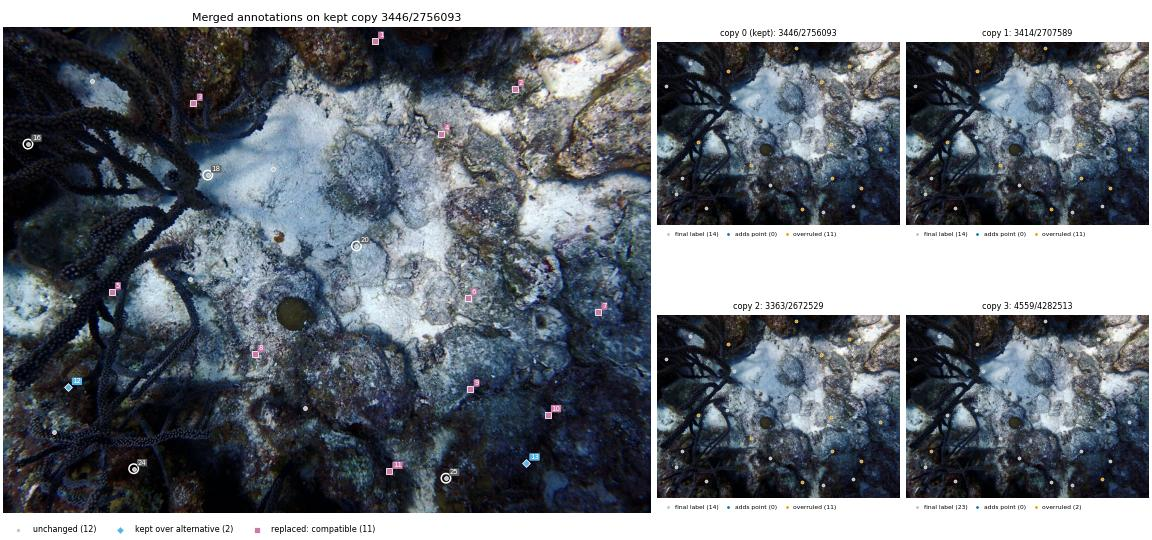

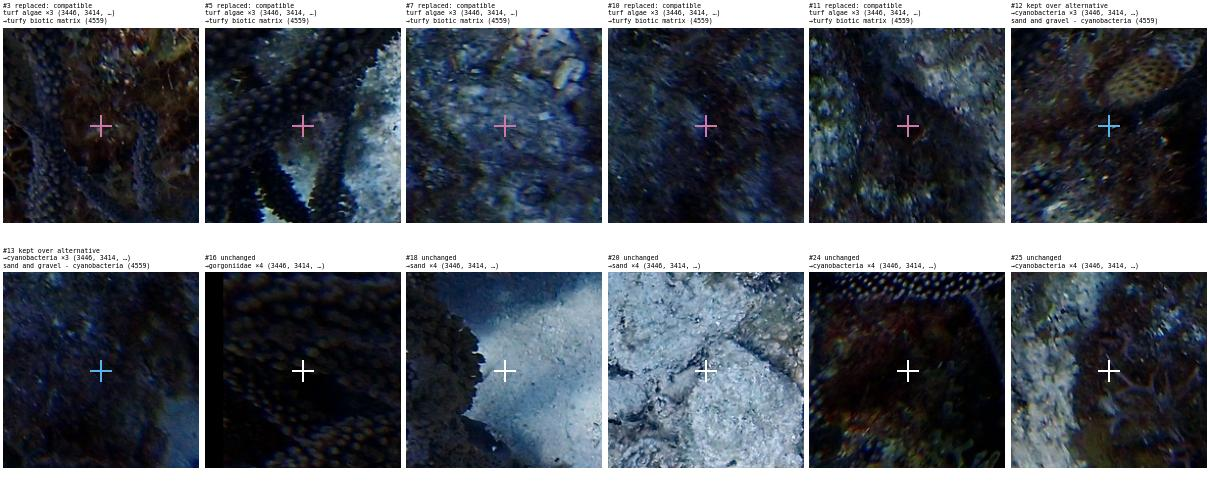

,status,row,col,final_label,from,kept_copy_label,labels_by_copy
nr,,,,,,,
3,replaced: compatible,240,601,turfy biotic matrix,4559/4282513,turf algae,"turf algae ×3 (3446, 3414, 3363) | →turfy biotic matrix (4559)"
5,replaced: compatible,836,343,turfy biotic matrix,4559/4282513,turf algae,"turf algae ×3 (3446, 3414, 3363) | →turfy biotic matrix (4559)"
7,replaced: compatible,900,1880,turfy biotic matrix,4559/4282513,turf algae,"turf algae ×3 (3446, 3414, 3363) | →turfy biotic matrix (4559)"
10,replaced: compatible,1224,1720,turfy biotic matrix,4559/4282513,turf algae,"turf algae ×3 (3446, 3414, 3363) | →turfy biotic matrix (4559)"
11,replaced: compatible,1403,1219,turfy biotic matrix,4559/4282513,turf algae,"turf algae ×3 (3446, 3414, 3363) | →turfy biotic matrix (4559)"
12,kept over alternative,1138,206,cyanobacteria,3446/2756093,cyanobacteria,"→cyanobacteria ×3 (3446, 3414, 3363) | sand and gravel - cyanobacteria (4559)"
13,kept over alternative,1377,1652,cyanobacteria,3446/2756093,cyanobacteria,"→cyanobacteria ×3 (3446, 3414, 3363) | sand and gravel - cyanobacteria (4559)"
16,unchanged,369,78,gorgoniidae,3446/2756093,gorgoniidae,"→gorgoniidae ×4 (3446, 3414, 3363, 4559)"
18,unchanged,467,646,sand,3446/2756093,sand,"→sand ×4 (3446, 3414, 3363, 4559)"


… 3 more points: r.show('c9b585e686678350ce7e81152a441519', max_rows=None) for all


---
### Image `ba93b6d09a3b`
**Kept copy: 3446/2756121** (carib_bitbybit; new split: train), one of 4 byte-identical copies in 4 source(s).
Why this copy: best-ranked source in conflict cluster 3 (rank 5 vs 3414's rank 6).
Merged result: 25 points (25 from the kept copy, 0 added from other copies).
- **replaced: compatible** (5): labels don't clash but none covers the other; label with most taxonomic ranks used
- **kept over alternative** (1): kept copy's label stayed; another copy had a coarser/synonym/unmapped label
Annotations for this image are **overridden** in the dataset.

,kept,source,image_id,name,new_split,cluster,source_rank,n_points,points_at_merged_locs
copy,,,,,,,,,
0,True,3446,2756121,carib_bitbybit,train,3,5,25,25
1,False,3414,2707847,curacao,train,3,6,25,25
2,False,3363,2672787,carib,train,3,7,25,25
3,False,4559,4283490,Curacao Coral Reef Assessment 2023,train,3,12,25,25


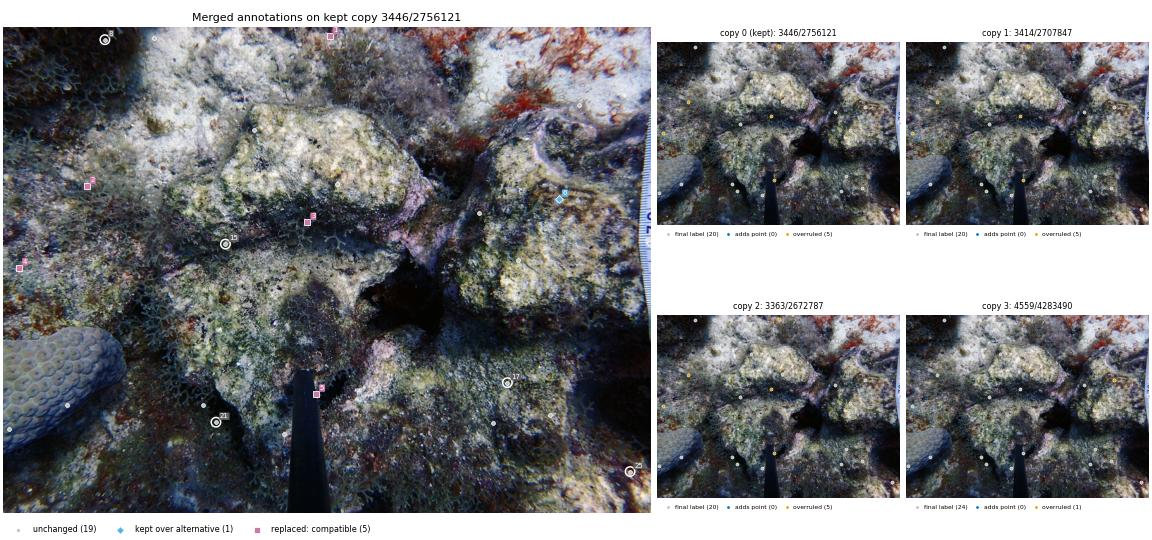

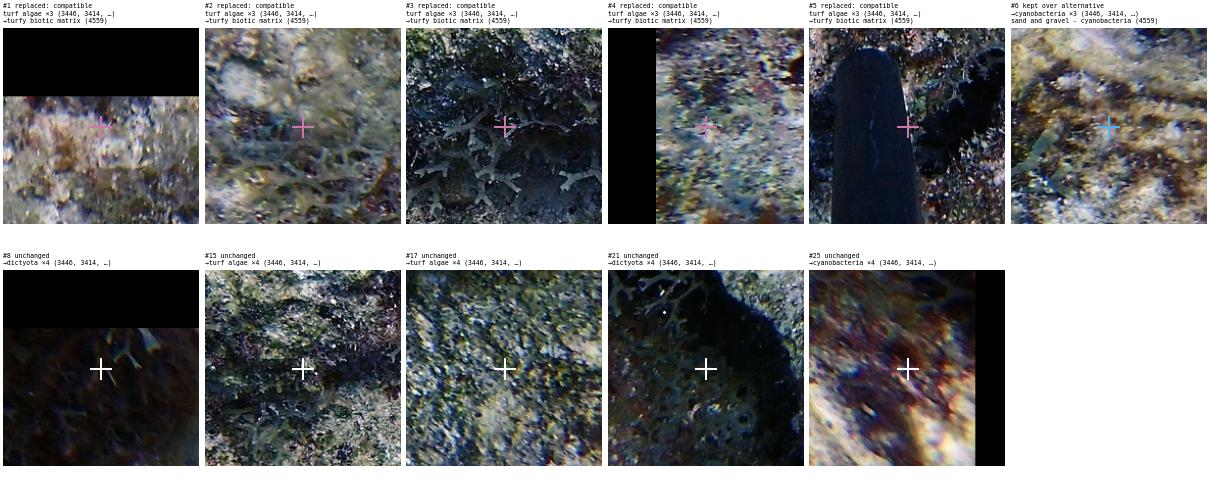

,status,row,col,final_label,from,kept_copy_label,labels_by_copy
nr,,,,,,,
1,replaced: compatible,29,1031,turfy biotic matrix,4559/4283490,turf algae,"turf algae ×3 (3446, 3414, 3363) | →turfy biotic matrix (4559)"
2,replaced: compatible,502,263,turfy biotic matrix,4559/4283490,turf algae,"turf algae ×3 (3446, 3414, 3363) | →turfy biotic matrix (4559)"
3,replaced: compatible,616,960,turfy biotic matrix,4559/4283490,turf algae,"turf algae ×3 (3446, 3414, 3363) | →turfy biotic matrix (4559)"
4,replaced: compatible,760,49,turfy biotic matrix,4559/4283490,turf algae,"turf algae ×3 (3446, 3414, 3363) | →turfy biotic matrix (4559)"
5,replaced: compatible,1159,988,turfy biotic matrix,4559/4283490,turf algae,"turf algae ×3 (3446, 3414, 3363) | →turfy biotic matrix (4559)"
6,kept over alternative,543,1755,cyanobacteria,3446/2756121,cyanobacteria,"→cyanobacteria ×3 (3446, 3414, 3363) | sand and gravel - cyanobacteria (4559)"
8,unchanged,39,321,dictyota,3446/2756121,dictyota,"→dictyota ×4 (3446, 3414, 3363, 4559)"
15,unchanged,685,702,turf algae,3446/2756121,turf algae,"→turf algae ×4 (3446, 3414, 3363, 4559)"
17,unchanged,1123,1593,turf algae,3446/2756121,turf algae,"→turf algae ×4 (3446, 3414, 3363, 4559)"


In [5]:
r.show_many(r.select("replaced: compatible", n=2, seed=0))

## 4. Replaced: kept copy's label not in `class_to_concepts.csv`

About 25.6k labels changed this way, the second-largest group of replacements.

---
### Image `dbbca846d519`
**Kept copy: 7104/5621803** (BYS New Classifier; new split: train), one of 4 byte-identical copies in 4 source(s).
Why this copy: best-ranked source in conflict cluster 8 (rank 1 vs 7075's rank 2).
Merged result: 75 points (75 from the kept copy, 0 added from other copies).
- **replaced: unmapped label** (41): kept copy's label not in class_to_concepts.csv; another copy's label used
Annotations for this image are **overridden** in the dataset.

,kept,source,image_id,name,new_split,cluster,source_rank,n_points,points_at_merged_locs
copy,,,,,,,,,
0,True,7104,5621803,BYS New Classifier,train,8,1,75,75
1,False,7075,5623907,(private/deleted),train,8,2,75,75
2,False,7027,5582482,(private/deleted),train,8,3,75,75
3,False,6695,5402794,(private/deleted),train,8,4,75,75


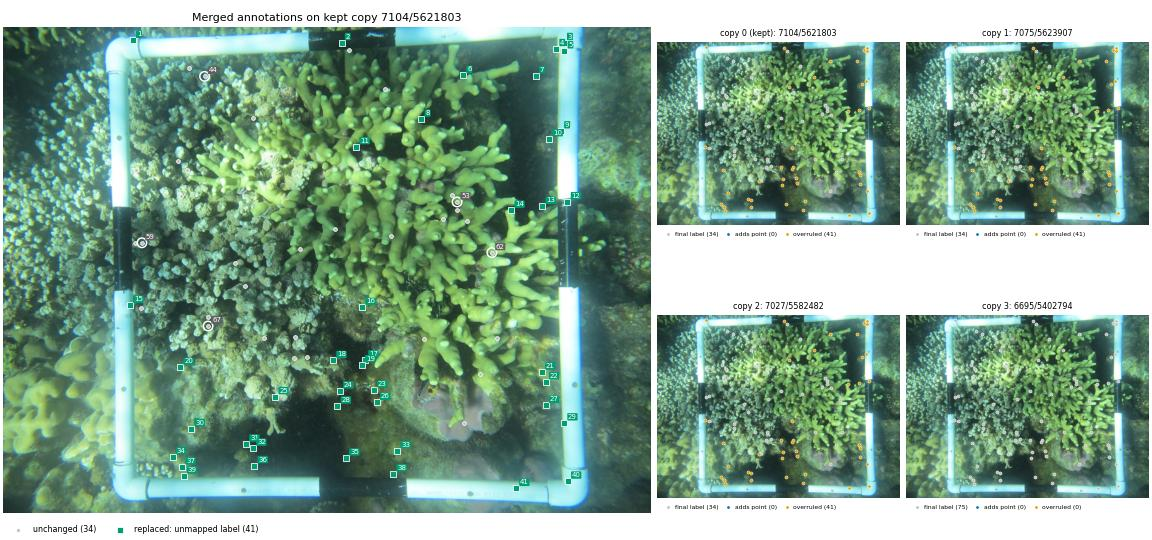

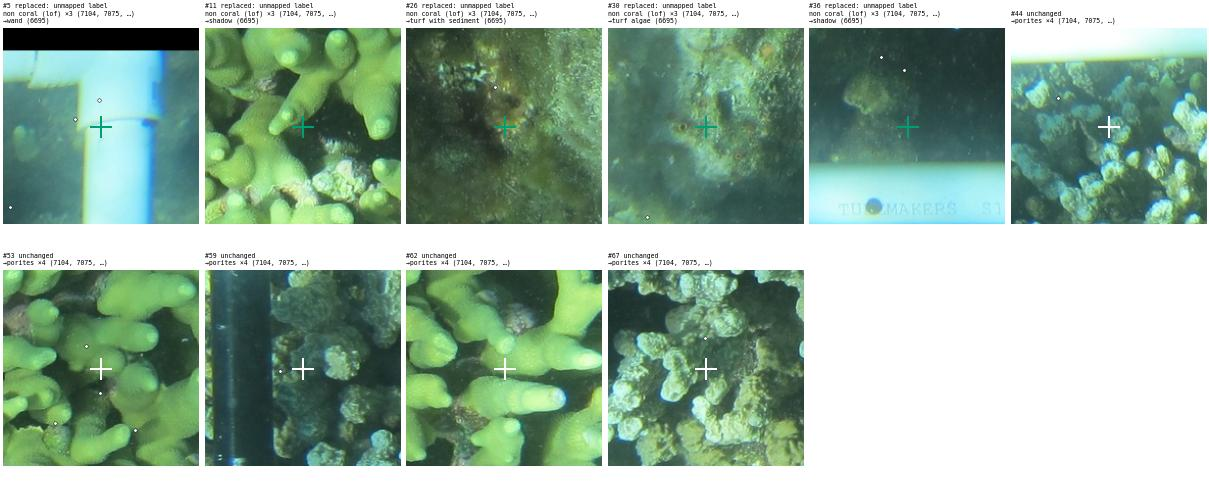

,status,row,col,final_label,from,kept_copy_label,labels_by_copy
nr,,,,,,,
5,replaced: unmapped label,74,1773,wand,6695/5402794,non coral (lof),"non coral (lof) ×3 (7104, 7075, 7027) | →wand (6695)"
11,replaced: unmapped label,377,1115,shadow,6695/5402794,non coral (lof),"non coral (lof) ×3 (7104, 7075, 7027) | →shadow (6695)"
26,replaced: unmapped label,1185,1180,turf with sediment,6695/5402794,non coral (lof),"non coral (lof) ×3 (7104, 7075, 7027) | →turf with sediment (6695)"
30,replaced: unmapped label,1268,594,turf algae,6695/5402794,non coral (lof),"non coral (lof) ×3 (7104, 7075, 7027) | →turf algae (6695)"
36,replaced: unmapped label,1385,793,shadow,6695/5402794,non coral (lof),"non coral (lof) ×3 (7104, 7075, 7027) | →shadow (6695)"
44,unchanged,155,636,porites,7104/5621803,porites,"→porites ×4 (7104, 7075, 7027, 6695)"
53,unchanged,552,1434,porites,7104/5621803,porites,"→porites ×4 (7104, 7075, 7027, 6695)"
59,unchanged,681,438,porites,7104/5621803,porites,"→porites ×4 (7104, 7075, 7027, 6695)"
62,unchanged,712,1544,porites,7104/5621803,porites,"→porites ×4 (7104, 7075, 7027, 6695)"


… 31 more points: r.show('dbbca846d519f03d17d47f30e31c1485', max_rows=None) for all


---
### Image `b4c59c532c5a`
**Kept copy: 7027/5582700** (private/deleted source; new split: train), one of 2 byte-identical copies in 2 source(s).
Why this copy: best-ranked source in conflict cluster 8 (rank 3 vs 6695's rank 4).
Merged result: 75 points (75 from the kept copy, 0 added from other copies).
- **replaced: unmapped label** (62): kept copy's label not in class_to_concepts.csv; another copy's label used
Annotations for this image are **overridden** in the dataset.

,kept,source,image_id,name,new_split,cluster,source_rank,n_points,points_at_merged_locs
copy,,,,,,,,,
0,True,7027,5582700,(private/deleted),train,8,3,75,75
1,False,6695,5415252,(private/deleted),train,8,4,75,75


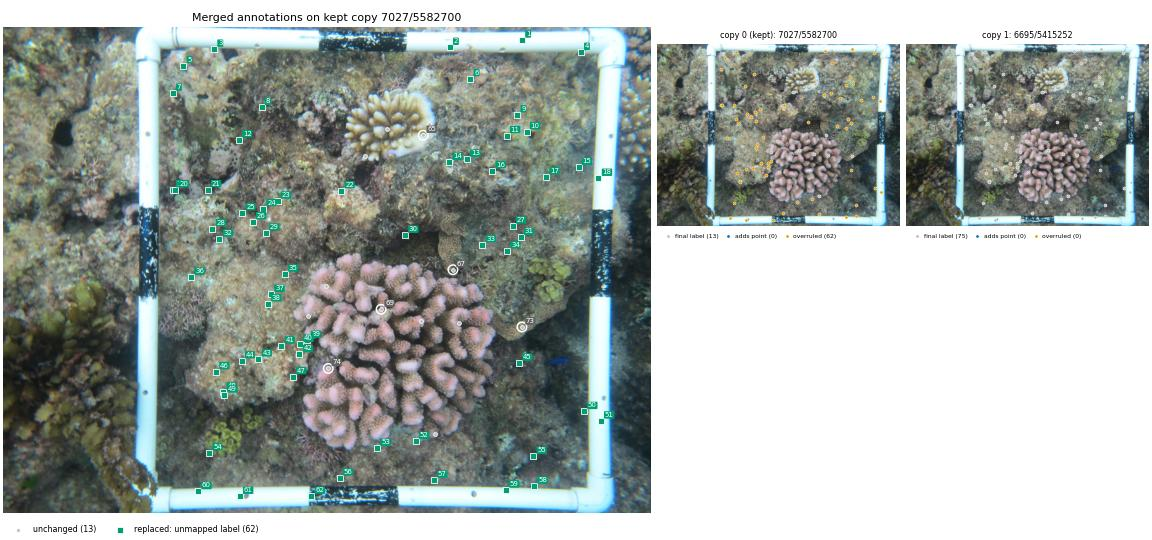

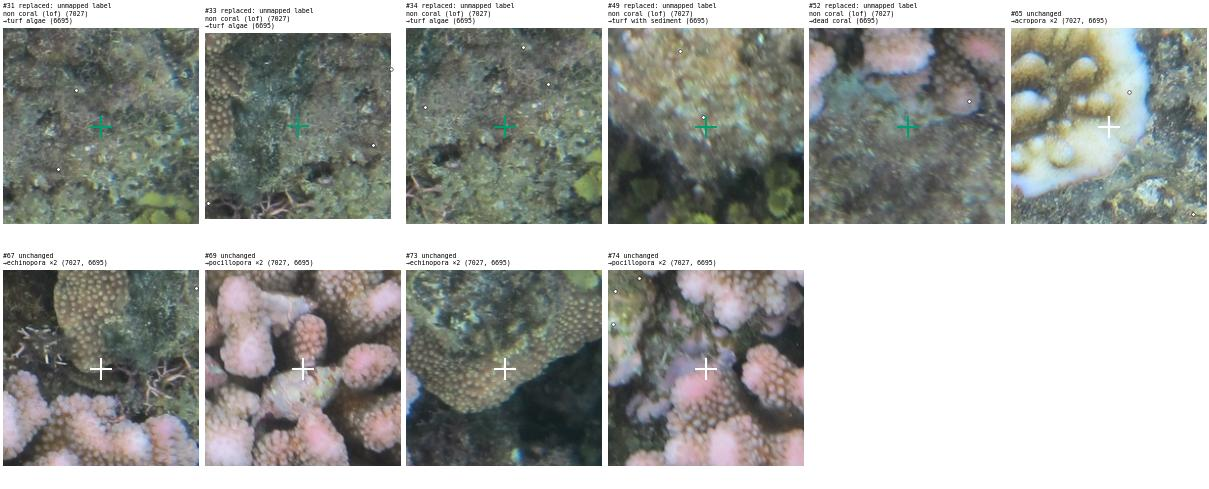

,status,row,col,final_label,from,kept_copy_label,labels_by_copy
nr,,,,,,,
31,replaced: unmapped label,664,1635,turf algae,6695/5415252,non coral (lof),non coral (lof) (7027) | →turf algae (6695)
33,replaced: unmapped label,687,1514,turf algae,6695/5415252,non coral (lof),non coral (lof) (7027) | →turf algae (6695)
34,replaced: unmapped label,706,1592,turf algae,6695/5415252,non coral (lof),non coral (lof) (7027) | →turf algae (6695)
49,replaced: unmapped label,1162,698,turf with sediment,6695/5415252,non coral (lof),non coral (lof) (7027) | →turf with sediment (6695)
52,replaced: unmapped label,1309,1304,dead coral,6695/5415252,non coral (lof),non coral (lof) (7027) | →dead coral (6695)
65,unchanged,341,1327,acropora,7027/5582700,acropora,"→acropora ×2 (7027, 6695)"
67,unchanged,766,1421,echinopora,7027/5582700,echinopora,"→echinopora ×2 (7027, 6695)"
69,unchanged,891,1194,pocillopora,7027/5582700,pocillopora,"→pocillopora ×2 (7027, 6695)"
73,unchanged,947,1639,echinopora,7027/5582700,echinopora,"→echinopora ×2 (7027, 6695)"


… 52 more points: r.show('b4c59c532c5a082cfb76df685110d5a0', max_rows=None) for all


In [6]:
r.show_many(r.select("replaced: unmapped label", n=2, seed=0))

## 5. Contradictory labels

The best-ranked copy's label is used for now. First the images with the most contradictory points, then a random sample.

---
### Image `ecbb01de0d51`
**Kept copy: 2048/1775866** (MBON_AR_CO_EC_US_Robot; new split: train), one of 9 byte-identical copies in 6 source(s).
Why this copy: best-ranked source in conflict cluster 4 (rank 2 vs 2562's rank 3).
Merged result: 200 points (100 from the kept copy, 23 added from other copies).
- **contradictory** (142): labels clash; best-ranked copy's label used — **check these**
- **added** (23): points only another copy had, added as is
- **kept over alternative** (5): kept copy's label stayed; another copy had a coarser/synonym/unmapped label
Annotations for this image are **overridden** in the dataset.

,kept,source,image_id,name,new_split,cluster,source_rank,n_points,points_at_merged_locs
copy,,,,,,,,,
0,True,2048,1775866,MBON_AR_CO_EC_US_Robot,train,4,2,100,100
1,False,2562,2032612,MBON_Robot Training,train,4,3,100,100
2,False,1983,1732478,MBON_Colombia,train,4,5,100,100
3,False,1972,1720924,MBON_AR_CO_EC,train,4,6,100,100
4,False,1972,1756970,MBON_AR_CO_EC,train,4,6,100,100
5,False,1972,1763287,MBON_AR_CO_EC,train,4,6,100,100


… 3 more copies (max_copies=None to show all)


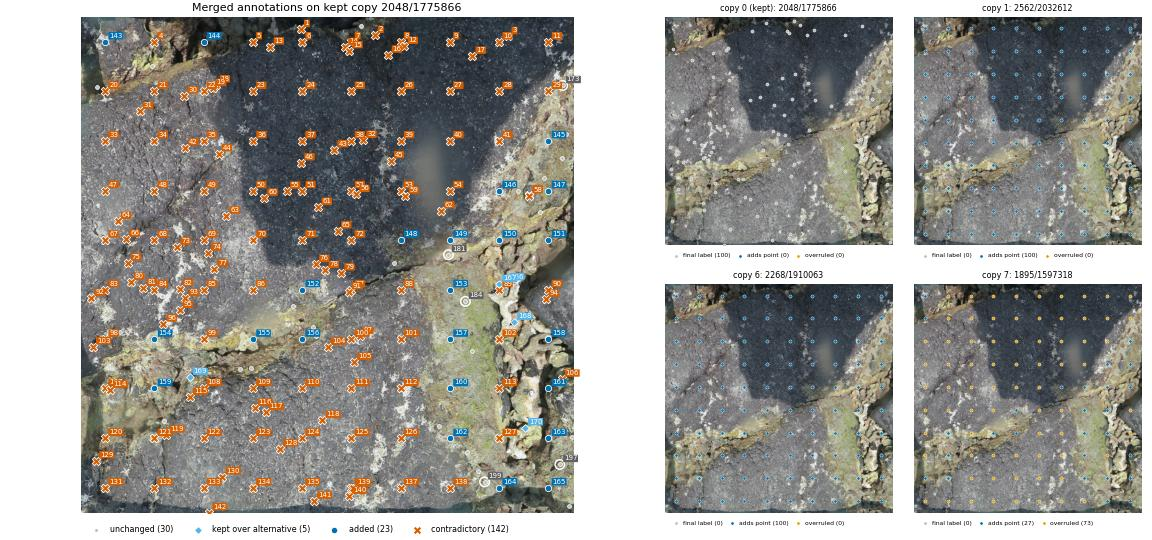

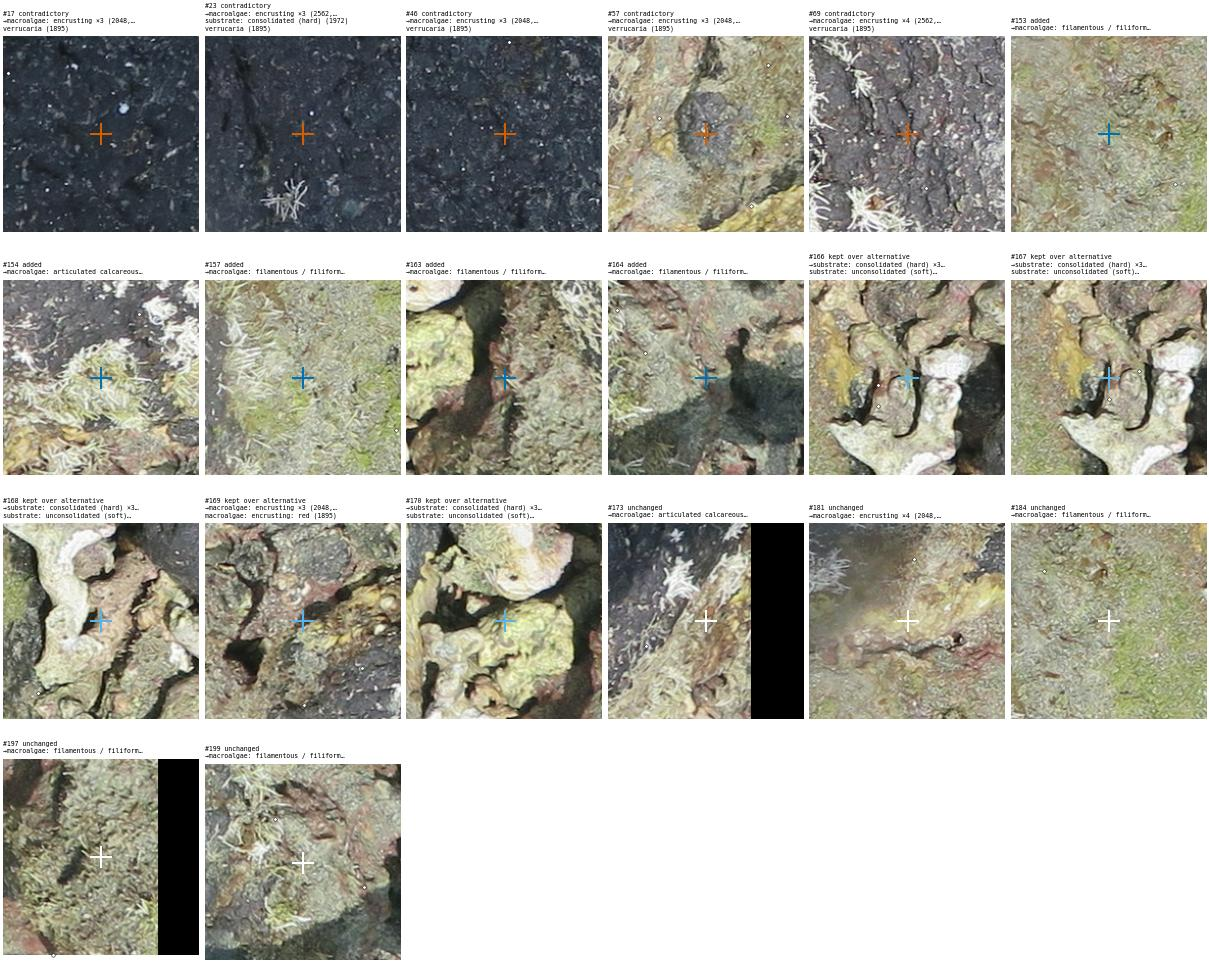

,status,row,col,final_label,from,kept_copy_label,labels_by_copy
nr,,,,,,,
17,contradictory,161,1617,macroalgae: encrusting,2048/1775866,macroalgae: encrusting,"→macroalgae: encrusting ×3 (2048, 1983, 1972) | verrucaria (1895)"
23,contradictory,306,711,macroalgae: encrusting,2562/2032612,—,"→macroalgae: encrusting ×3 (2562, 1972, 2268) | substrate: consolidated (hard) (1972) | verrucaria (1895)"
46,contradictory,601,910,macroalgae: encrusting,2048/1775866,macroalgae: encrusting,"→macroalgae: encrusting ×3 (2048, 1983, 1972) | verrucaria (1895)"
57,contradictory,734,1853,macroalgae: encrusting,2048/1775866,macroalgae: encrusting,"→macroalgae: encrusting ×3 (2048, 1983, 1972) | verrucaria (1895)"
69,contradictory,920,507,macroalgae: encrusting,2562/2032612,—,"→macroalgae: encrusting ×4 (2562, 1972, 2268) | verrucaria (1895)"
153,added,1125,1525,macroalgae: filamentous / filiform,2562/2032612,—,"→macroalgae: filamentous / filiform ×5 (2562, 1972, 2268, 1895)"
154,added,1330,304,macroalgae: articulated calcareous,2562/2032612,—,"→macroalgae: articulated calcareous ×5 (2562, 1972, 2268, 1895)"
157,added,1330,1525,macroalgae: filamentous / filiform,2562/2032612,—,"→macroalgae: filamentous / filiform ×5 (2562, 1972, 2268, 1895)"
163,added,1740,1932,macroalgae: filamentous / filiform,2562/2032612,—,"→macroalgae: filamentous / filiform ×5 (2562, 1972, 2268, 1895)"


… 160 more points: r.show('ecbb01de0d516f50ca4f722be5b38be3', max_rows=None) for all


---
### Image `139b7e84d096`
**Kept copy: 2565/2032895** (MBON_Robot Training (Southamerica); new split: train), one of 10 byte-identical copies in 7 source(s).
Why this copy: best-ranked source in conflict cluster 4 (rank 1 vs 2048's rank 2).
Merged result: 200 points (100 from the kept copy, 38 added from other copies).
- **contradictory** (132): labels clash; best-ranked copy's label used — **check these**
- **added** (38): points only another copy had, added as is
- **kept over alternative** (9): kept copy's label stayed; another copy had a coarser/synonym/unmapped label
Annotations for this image are **overridden** in the dataset.

,kept,source,image_id,name,new_split,cluster,source_rank,n_points,points_at_merged_locs
copy,,,,,,,,,
0,True,2565,2032895,MBON_Robot Training (Southamerica),train,4,1,100,100
1,False,2048,1775863,MBON_AR_CO_EC_US_Robot,train,4,2,100,100
2,False,2562,2032264,MBON_Robot Training,train,4,3,100,100
3,False,1983,1732449,MBON_Colombia,train,4,5,100,100
4,False,1972,1720927,MBON_AR_CO_EC,train,4,6,100,100
5,False,1972,1756963,MBON_AR_CO_EC,train,4,6,100,100


… 4 more copies (max_copies=None to show all)


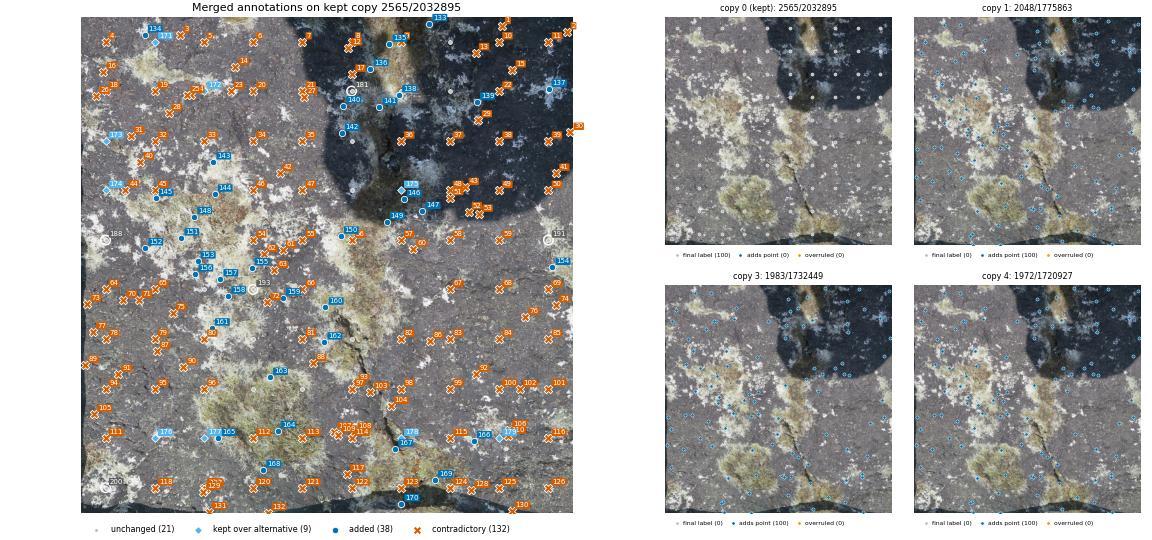

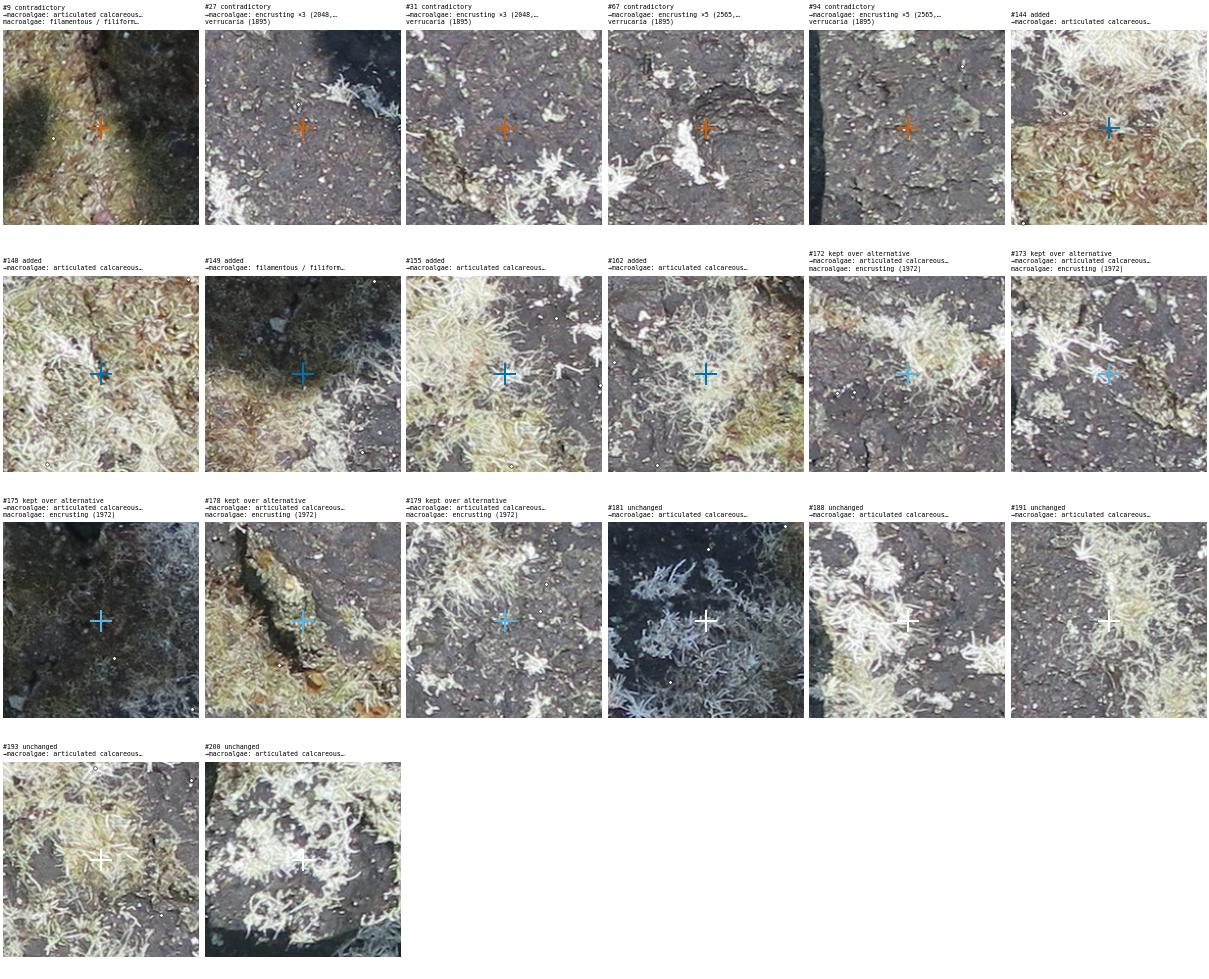

,status,row,col,final_label,from,kept_copy_label,labels_by_copy
nr,,,,,,,
9,contradictory,101,1319,macroalgae: articulated calcareous,2565/2032895,macroalgae: articulated calcareous,"→macroalgae: articulated calcareous ×5 (2565, 2562, 1972, 2268, …) | macroalgae: filamentous / filiform (1972)"
27,contradictory,328,918,macroalgae: encrusting,2048/1775863,—,"→macroalgae: encrusting ×3 (2048, 1983, 1972) | verrucaria (1895)"
31,contradictory,490,204,macroalgae: encrusting,2048/1775863,—,"→macroalgae: encrusting ×3 (2048, 1983, 1972) | verrucaria (1895)"
67,contradictory,1124,1522,macroalgae: encrusting,2565/2032895,macroalgae: encrusting,"→macroalgae: encrusting ×5 (2565, 2562, 1972, 2268) | verrucaria (1895)"
94,contradictory,1534,100,macroalgae: encrusting,2565/2032895,macroalgae: encrusting,"→macroalgae: encrusting ×5 (2565, 2562, 1972, 2268) | verrucaria (1895)"
144,added,730,550,macroalgae: articulated calcareous,2048/1775863,—,"→macroalgae: articulated calcareous ×4 (2048, 1983, 1972, 1895)"
148,added,823,465,macroalgae: articulated calcareous,2048/1775863,—,"→macroalgae: articulated calcareous ×4 (2048, 1983, 1972, 1895)"
149,added,844,1261,macroalgae: filamentous / filiform,2048/1775863,—,"→macroalgae: filamentous / filiform ×4 (2048, 1983, 1972, 1895)"
155,added,1034,703,macroalgae: articulated calcareous,2048/1775863,—,"→macroalgae: articulated calcareous ×4 (2048, 1983, 1972, 1895)"


… 169 more points: r.show('139b7e84d096fc6af0cb87ae06d34bfe', max_rows=None) for all


In [7]:
r.show_many(r.select("contradictory", order="most", n=2))

---
### Image `b6b355d90a1f`
**Kept copy: 4721/4105141** (Thuwal Bleaching Conditions; new split: train), one of 2 byte-identical copies in 2 source(s).
Why this copy: best-ranked source in conflict cluster 7 (rank 1 vs 4710's rank 2).
Merged result: 50 points (50 from the kept copy, 0 added from other copies).
- **contradictory** (15): labels clash; best-ranked copy's label used — **check these**
Annotations for this image are unchanged in the dataset (the kept copy's own points are used).

,kept,source,image_id,name,new_split,cluster,source_rank,n_points,points_at_merged_locs
copy,,,,,,,,,
0,True,4721,4105141,Thuwal Bleaching Conditions,train,7,1,50,50
1,False,4710,4105216,Thuwal Bleaching Taxonomic,train,7,2,50,50


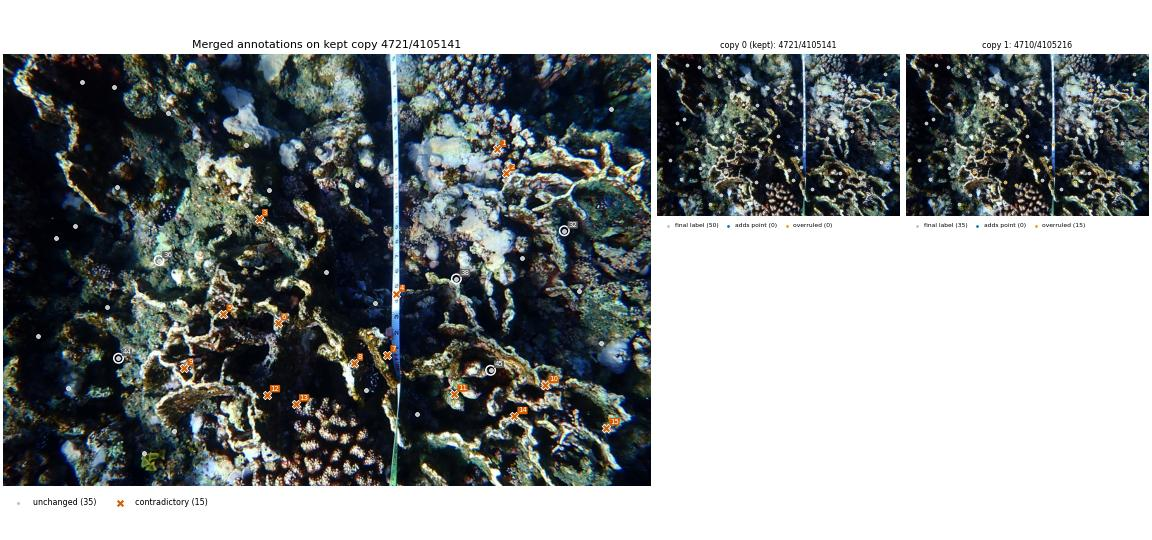

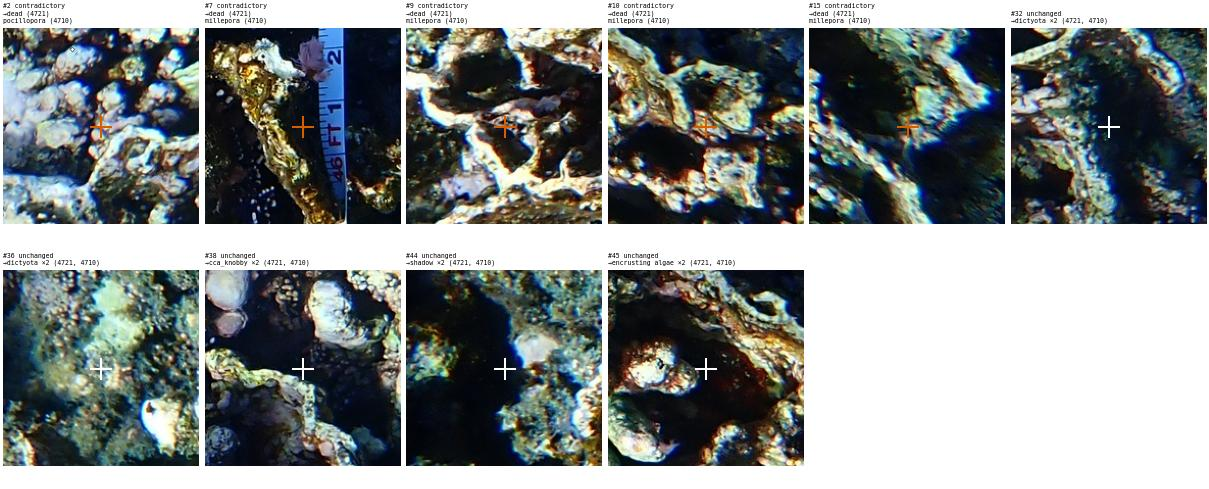

,status,row,col,final_label,from,kept_copy_label,labels_by_copy
nr,,,,,,,
2,contradictory,378,1589,dead,4721/4105141,dead,→dead (4721) | pocillopora (4710)
7,contradictory,951,1213,dead,4721/4105141,dead,→dead (4721) | millepora (4710)
9,contradictory,992,572,dead,4721/4105141,dead,→dead (4721) | millepora (4710)
10,contradictory,1048,1713,dead,4721/4105141,dead,→dead (4721) | millepora (4710)
15,contradictory,1181,1905,dead,4721/4105141,dead,→dead (4721) | millepora (4710)
32,unchanged,559,1773,dictyota,4721/4105141,dictyota,"→dictyota ×2 (4721, 4710)"
36,unchanged,653,492,dictyota,4721/4105141,dictyota,"→dictyota ×2 (4721, 4710)"
38,unchanged,711,1432,cca_knobby,4721/4105141,cca_knobby,"→cca_knobby ×2 (4721, 4710)"
44,unchanged,962,364,shadow,4721/4105141,shadow,"→shadow ×2 (4721, 4710)"


… 5 more points: r.show('b6b355d90a1ff910acd3c97df7e3d41a', max_rows=None) for all


---
### Image `0d579037382b`
**Kept copy: 3499/2911110** (mal100; new split: train), one of 8 byte-identical copies in 8 source(s).
Why this copy: best-ranked source in conflict cluster 1 (rank 1 vs 3497's rank 2).
Merged result: 25 points (25 from the kept copy, 0 added from other copies).
- **contradictory** (3): labels clash; best-ranked copy's label used — **check these**
- **kept over alternative** (2): kept copy's label stayed; another copy had a coarser/synonym/unmapped label
Annotations for this image are unchanged in the dataset (the kept copy's own points are used).

,kept,source,image_id,name,new_split,cluster,source_rank,n_points,points_at_merged_locs
copy,,,,,,,,,
0,True,3499,2911110,mal100,train,1,1,25,25
1,False,3497,2905503,Maldives_bitbybit3,train,1,2,25,25
2,False,3551,2982245,2Maldives_2Katie,train,1,3,25,25
3,False,3460,2787393,Maldives_Katie,train,1,9,25,25
4,False,3416,2713170,maldives_check2020,train,1,10,25,25
5,False,3401,2653905,Maldives_2022,train,1,12,25,25


… 2 more copies (max_copies=None to show all)


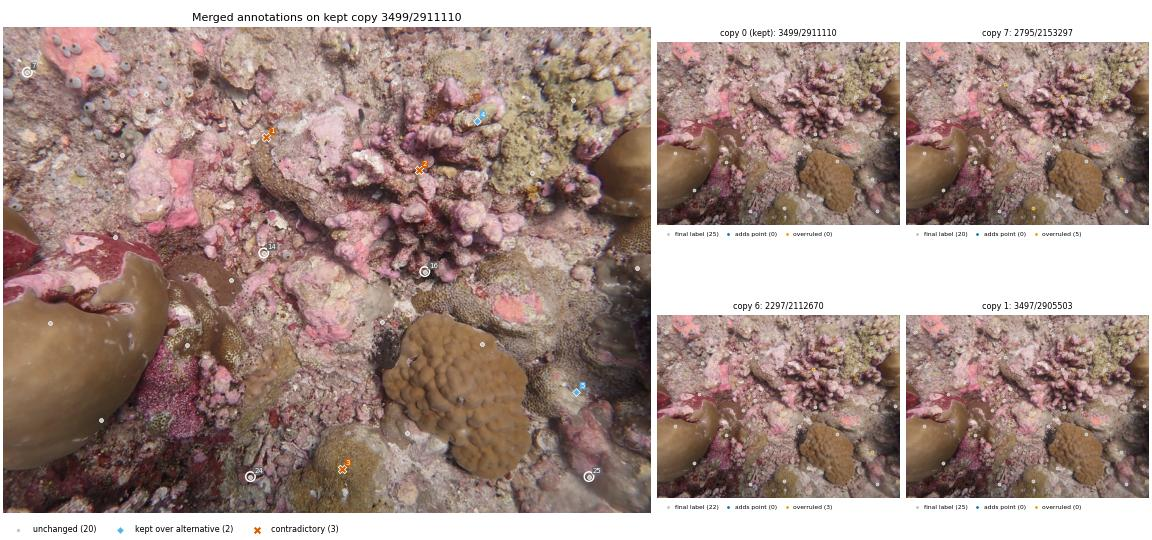

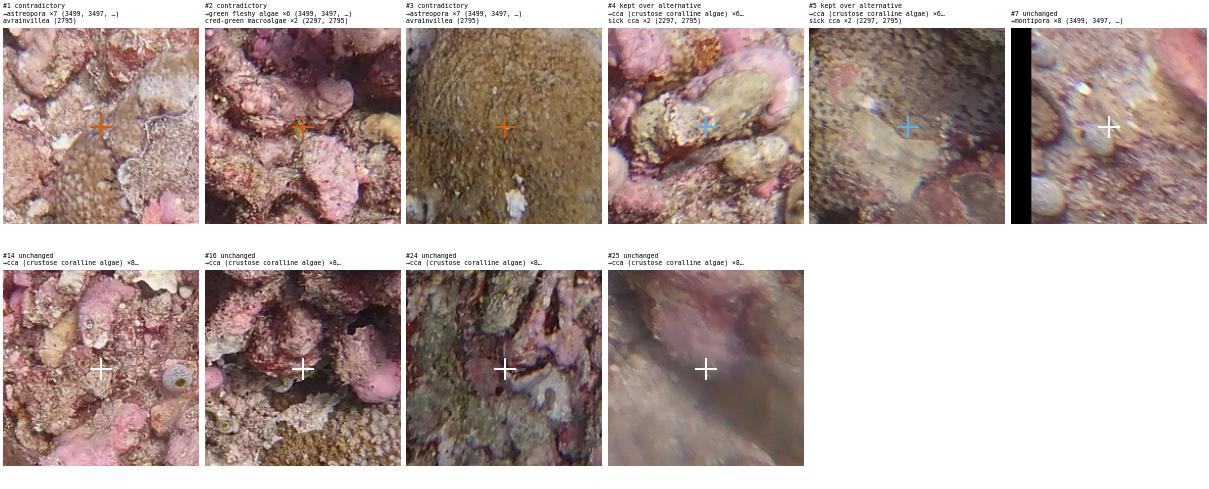

,status,row,col,final_label,from,kept_copy_label,labels_by_copy
nr,,,,,,,
1,contradictory,348,831,astreopora,3499/2911110,astreopora,"→astreopora ×7 (3499, 3497, 3551, 3460, …) | avrainvillea (2795)"
2,contradictory,452,1313,green fleshy algae,3499/2911110,green fleshy algae,"→green fleshy algae ×6 (3499, 3497, 3551, 3460, …) | cred-green macroalgae ×2 (2297, 2795)"
3,contradictory,1395,1070,astreopora,3499/2911110,astreopora,"→astreopora ×7 (3499, 3497, 3551, 3460, …) | avrainvillea (2795)"
4,kept over alternative,295,1496,cca (crustose coralline algae),3499/2911110,cca (crustose coralline algae),"→cca (crustose coralline algae) ×6 (3499, 3497, 3551, 3460, …) | sick cca ×2 (2297, 2795)"
5,kept over alternative,1152,1811,cca (crustose coralline algae),3499/2911110,cca (crustose coralline algae),"→cca (crustose coralline algae) ×6 (3499, 3497, 3551, 3460, …) | sick cca ×2 (2297, 2795)"
7,unchanged,142,76,montipora,3499/2911110,montipora,"→montipora ×8 (3499, 3497, 3551, 3460, …)"
14,unchanged,713,823,cca (crustose coralline algae),3499/2911110,cca (crustose coralline algae),"→cca (crustose coralline algae) ×8 (3499, 3497, 3551, 3460, …)"
16,unchanged,772,1332,cca (crustose coralline algae),3499/2911110,cca (crustose coralline algae),"→cca (crustose coralline algae) ×8 (3499, 3497, 3551, 3460, …)"
24,unchanged,1420,781,cca (crustose coralline algae),3499/2911110,cca (crustose coralline algae),"→cca (crustose coralline algae) ×8 (3499, 3497, 3551, 3460, …)"


In [8]:
r.show_many(r.select("contradictory", n=2, seed=1))

## 6. Kept over an alternative label

Nothing changed in the dataset, but another copy disagreed: it had a coarser, synonymous, compatible or unmapped label.

---
### Image `a608f342c63e`
**Kept copy: 3545/2955425** (cb4; new split: train), one of 5 byte-identical copies in 5 source(s).
Why this copy: best-ranked source in conflict cluster 3 (rank 2 vs 3479's rank 3).
Merged result: 25 points (25 from the kept copy, 0 added from other copies).
- **contradictory** (9): labels clash; best-ranked copy's label used — **check these**
- **kept over alternative** (14): kept copy's label stayed; another copy had a coarser/synonym/unmapped label
Annotations for this image are unchanged in the dataset (the kept copy's own points are used).

,kept,source,image_id,name,new_split,cluster,source_rank,n_points,points_at_merged_locs
copy,,,,,,,,,
0,True,3545,2955425,cb4,train,3,2,25,25
1,False,3479,2871205,cb3,train,3,3,25,25
2,False,3414,2701793,curacao,train,3,6,25,25
3,False,3363,2669894,carib,train,3,7,25,25
4,False,3443,2751010,carib_diploria,train,3,9,25,25


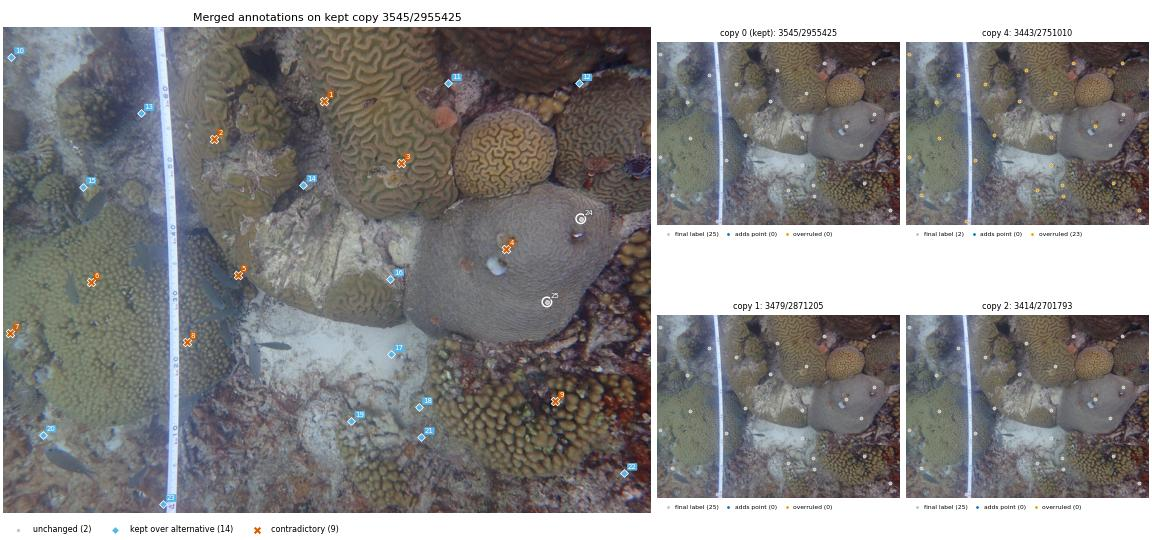

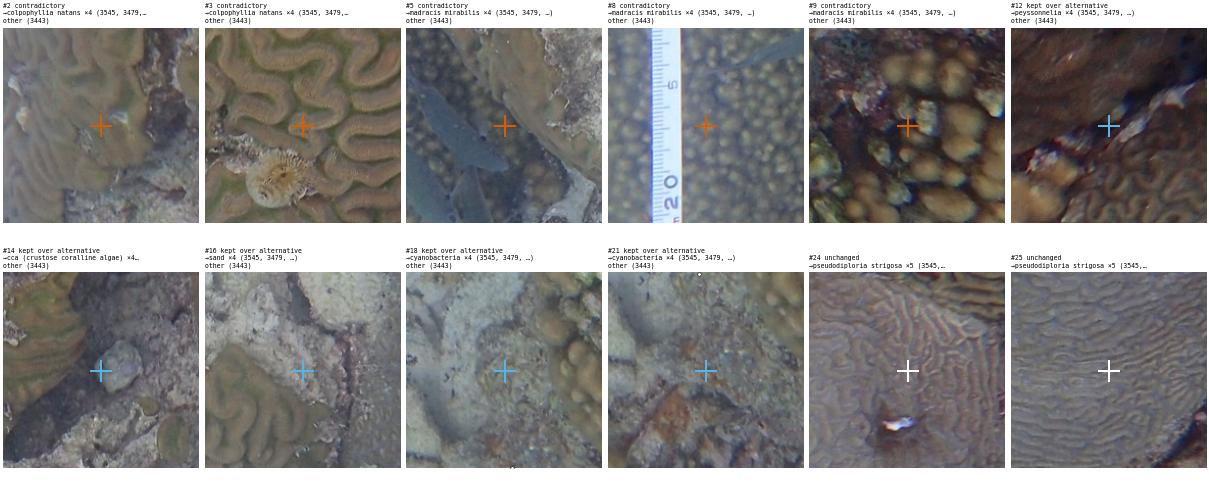

,status,row,col,final_label,from,kept_copy_label,labels_by_copy
nr,,,,,,,
2,contradictory,353,666,colpophyllia natans,3545/2955425,colpophyllia natans,"→colpophyllia natans ×4 (3545, 3479, 3414, 3363) | other (3443)"
3,contradictory,429,1258,colpophyllia natans,3545/2955425,colpophyllia natans,"→colpophyllia natans ×4 (3545, 3479, 3414, 3363) | other (3443)"
5,contradictory,782,741,madracis mirabilis,3545/2955425,madracis mirabilis,"→madracis mirabilis ×4 (3545, 3479, 3414, 3363) | other (3443)"
8,contradictory,994,580,madracis mirabilis,3545/2955425,madracis mirabilis,"→madracis mirabilis ×4 (3545, 3479, 3414, 3363) | other (3443)"
9,contradictory,1181,1744,madracis mirabilis,3545/2955425,madracis mirabilis,"→madracis mirabilis ×4 (3545, 3479, 3414, 3363) | other (3443)"
12,kept over alternative,177,1818,peyssonnelia,3545/2955425,peyssonnelia,"→peyssonnelia ×4 (3545, 3479, 3414, 3363) | other (3443)"
14,kept over alternative,497,948,cca (crustose coralline algae),3545/2955425,cca (crustose coralline algae),"→cca (crustose coralline algae) ×4 (3545, 3479, 3414, 3363) | other (3443)"
16,kept over alternative,795,1223,sand,3545/2955425,sand,"→sand ×4 (3545, 3479, 3414, 3363) | other (3443)"
18,kept over alternative,1200,1313,cyanobacteria,3545/2955425,cyanobacteria,"→cyanobacteria ×4 (3545, 3479, 3414, 3363) | other (3443)"


… 10 more points: r.show('a608f342c63ef4aa61c6d99730d1e7f2', max_rows=None) for all


---
### Image `a9d747796e20`
**Kept copy: 3416/2714569** (maldives_check2020; new split: train), one of 4 byte-identical copies in 4 source(s).
Why this copy: best-ranked source in conflict cluster 1 (rank 10 vs 3401's rank 12).
Merged result: 25 points (25 from the kept copy, 0 added from other copies).
- **contradictory** (1): labels clash; best-ranked copy's label used — **check these**
- **kept over alternative** (2): kept copy's label stayed; another copy had a coarser/synonym/unmapped label
Annotations for this image are unchanged in the dataset (the kept copy's own points are used).

,kept,source,image_id,name,new_split,cluster,source_rank,n_points,points_at_merged_locs
copy,,,,,,,,,
0,True,3416,2714569,maldives_check2020,train,1,10,25,25
1,False,3401,2655379,Maldives_2022,train,1,12,25,25
2,False,2297,2116014,CoralNet_Assistance_Test_0921,train,1,13,25,25
3,False,2795,2154166,Maldives_2021,train,1,14,25,25


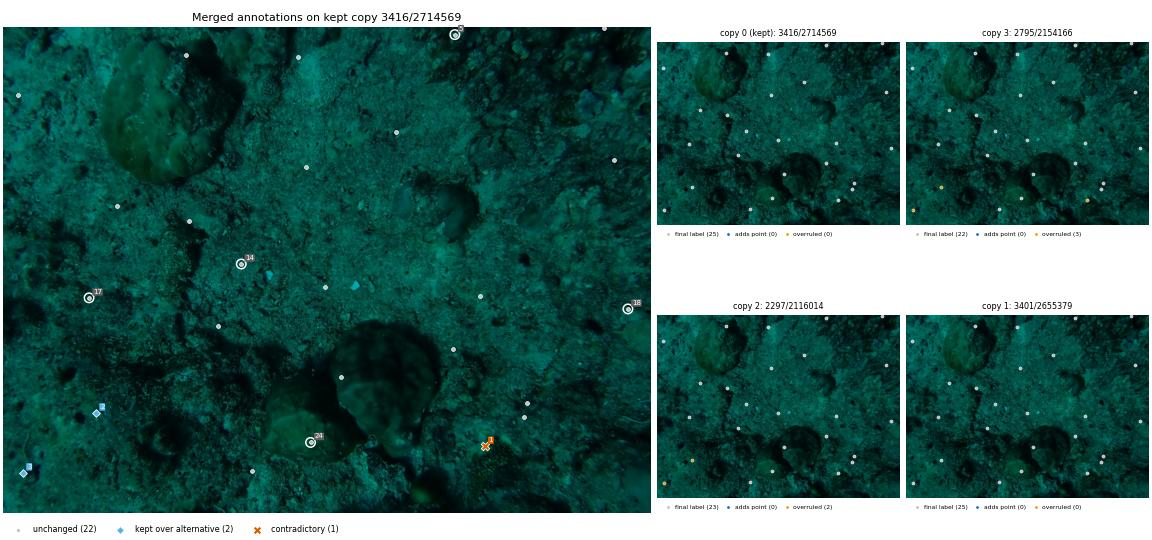

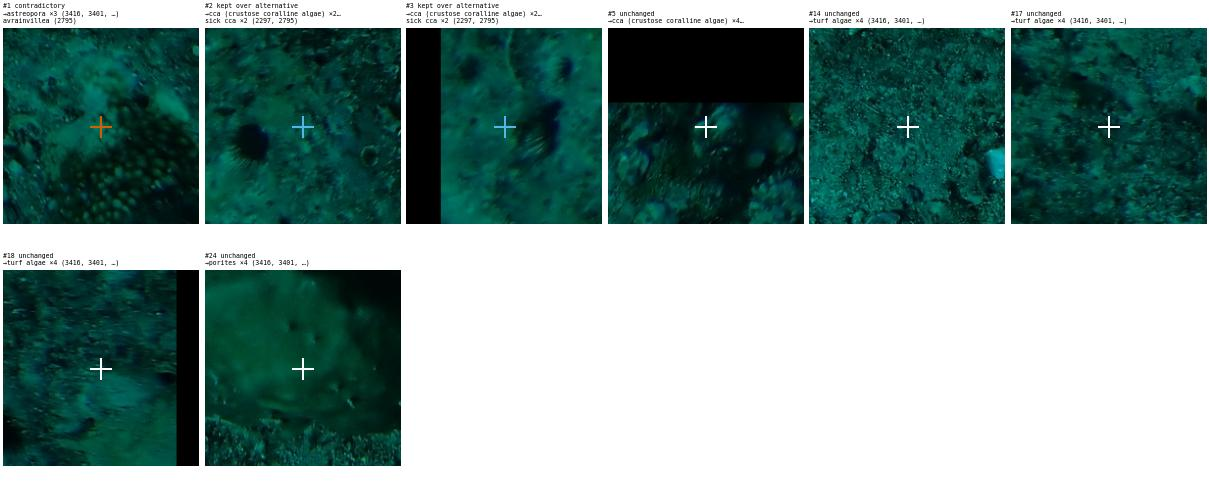

,status,row,col,final_label,from,kept_copy_label,labels_by_copy
nr,,,,,,,
1,contradictory,1324,1521,astreopora,3416/2714569,astreopora,"→astreopora ×3 (3416, 3401, 2297) | avrainvillea (2795)"
2,kept over alternative,1219,293,cca (crustose coralline algae),3416/2714569,cca (crustose coralline algae),"→cca (crustose coralline algae) ×2 (3416, 3401) | sick cca ×2 (2297, 2795)"
3,kept over alternative,1408,62,cca (crustose coralline algae),3416/2714569,cca (crustose coralline algae),"→cca (crustose coralline algae) ×2 (3416, 3401) | sick cca ×2 (2297, 2795)"
5,unchanged,23,1427,cca (crustose coralline algae),3416/2714569,cca (crustose coralline algae),"→cca (crustose coralline algae) ×4 (3416, 3401, 2297, 2795)"
14,unchanged,748,752,turf algae,3416/2714569,turf algae,"→turf algae ×4 (3416, 3401, 2297, 2795)"
17,unchanged,855,271,turf algae,3416/2714569,turf algae,"→turf algae ×4 (3416, 3401, 2297, 2795)"
18,unchanged,890,1974,turf algae,3416/2714569,turf algae,"→turf algae ×4 (3416, 3401, 2297, 2795)"
24,unchanged,1312,971,porites,3416/2714569,porites,"→porites ×4 (3416, 3401, 2297, 2795)"


In [9]:
r.show_many(r.select("kept over alternative", n=2, seed=0))

## 7. Clusters that cause most of the flags

- **4710 / 4721**: taxon vs bleaching condition. 4721 is kept, so its condition labels win on the contradictory points.
- **7569 cluster** (21 copies): pavement / cca / macroalgae vs "not coral" protocols.
- **7104, 6543 (vs 4229), 6956 (vs 6951)**.
- **2048 / 2562 / 1972 / 1895 (MBON)**: 9–10 copies per image; 1895 says "verrucaria" where the others say "macroalgae: encrusting".

Change `sources` to look at any other cluster.

===== sources [4710, 4721]


---
### Image `b9f9c9a7207a`
**Kept copy: 4721/4599804** (Thuwal Bleaching Conditions; new split: train), one of 2 byte-identical copies in 2 source(s).
Why this copy: best-ranked source in conflict cluster 7 (rank 1 vs 4710's rank 2).
Merged result: 50 points (50 from the kept copy, 0 added from other copies).
- **contradictory** (45): labels clash; best-ranked copy's label used — **check these**
Annotations for this image are unchanged in the dataset (the kept copy's own points are used).

,kept,source,image_id,name,new_split,cluster,source_rank,n_points,points_at_merged_locs
copy,,,,,,,,,
0,True,4721,4599804,Thuwal Bleaching Conditions,train,7,1,50,50
1,False,4710,4599803,Thuwal Bleaching Taxonomic,train,7,2,50,50


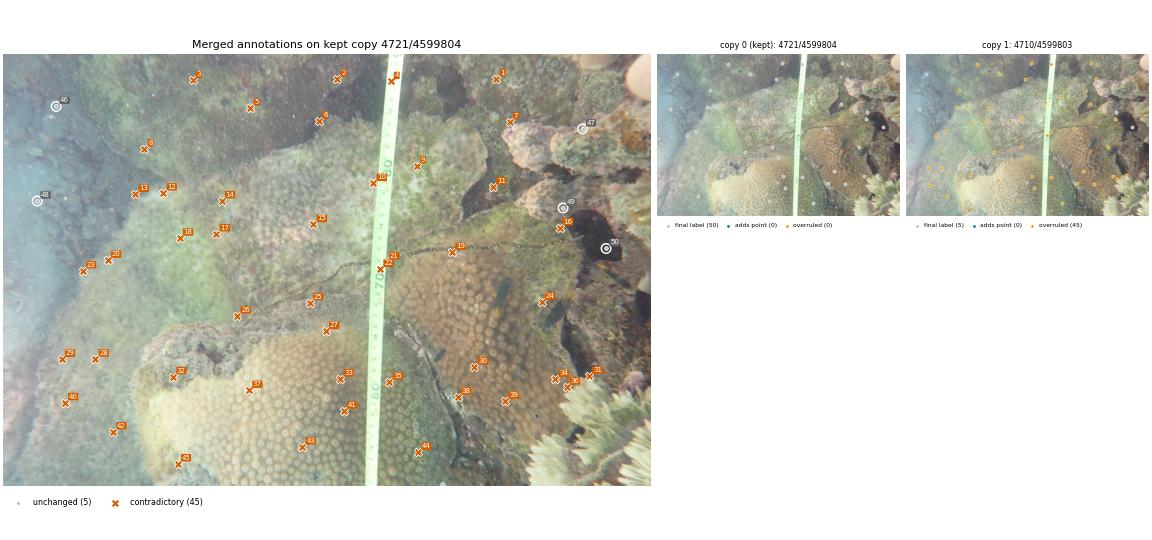

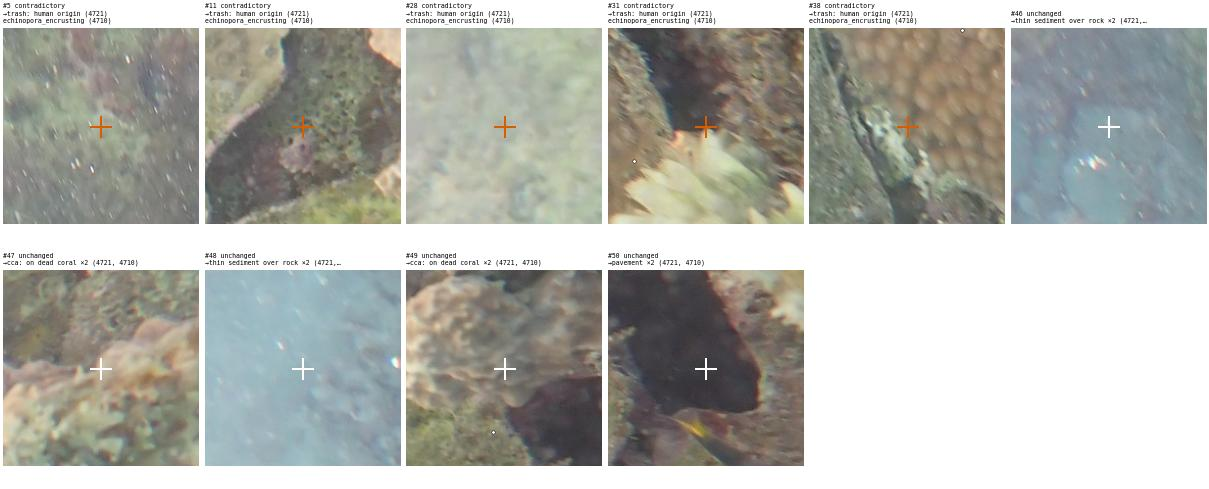

,status,row,col,final_label,from,kept_copy_label,labels_by_copy
nr,,,,,,,
5,contradictory,171,781,trash: human origin,4721/4599804,trash: human origin,→trash: human origin (4721) | echinopora_encrusting (4710)
11,contradictory,420,1547,trash: human origin,4721/4599804,trash: human origin,→trash: human origin (4721) | echinopora_encrusting (4710)
28,contradictory,964,291,trash: human origin,4721/4599804,trash: human origin,→trash: human origin (4721) | echinopora_encrusting (4710)
31,contradictory,1019,1851,trash: human origin,4721/4599804,trash: human origin,→trash: human origin (4721) | echinopora_encrusting (4710)
38,contradictory,1084,1436,trash: human origin,4721/4599804,trash: human origin,→trash: human origin (4721) | echinopora_encrusting (4710)
46,unchanged,166,167,thin sediment over rock,4721/4599804,thin sediment over rock,"→thin sediment over rock ×2 (4721, 4710)"
47,unchanged,237,1831,cca: on dead coral,4721/4599804,cca: on dead coral,"→cca: on dead coral ×2 (4721, 4710)"
48,unchanged,465,107,thin sediment over rock,4721/4599804,thin sediment over rock,"→thin sediment over rock ×2 (4721, 4710)"
49,unchanged,487,1769,cca: on dead coral,4721/4599804,cca: on dead coral,"→cca: on dead coral ×2 (4721, 4710)"


… 35 more points: r.show('b9f9c9a7207a08fc290112f5efbcd87c', max_rows=None) for all
===== sources [7569]


---
### Image `6713fa8ca43f`
**Kept copy: 7569/5828717** (private/deleted source; new split: train), one of 22 byte-identical copies in 22 source(s).
Why this copy: best-ranked source in conflict cluster 0 (rank 1 vs 7568's rank 2).
Merged result: 50 points (50 from the kept copy, 0 added from other copies).
- **contradictory** (50): labels clash; best-ranked copy's label used — **check these**
Annotations for this image are unchanged in the dataset (the kept copy's own points are used).

,kept,source,image_id,name,new_split,cluster,source_rank,n_points,points_at_merged_locs
copy,,,,,,,,,
0,True,7569,5828717,(private/deleted),train,0,1,50,50
1,False,7568,5828718,(private/deleted),train,0,2,50,50
2,False,6924,5514808,(private/deleted),train,0,3,50,50
3,False,6855,5487240,(private/deleted),train,0,7,50,50
4,False,6687,5390342,(private/deleted),train,0,8,50,50
5,False,6733,5440483,(private/deleted),train,0,13,50,50


… 16 more copies (max_copies=None to show all)


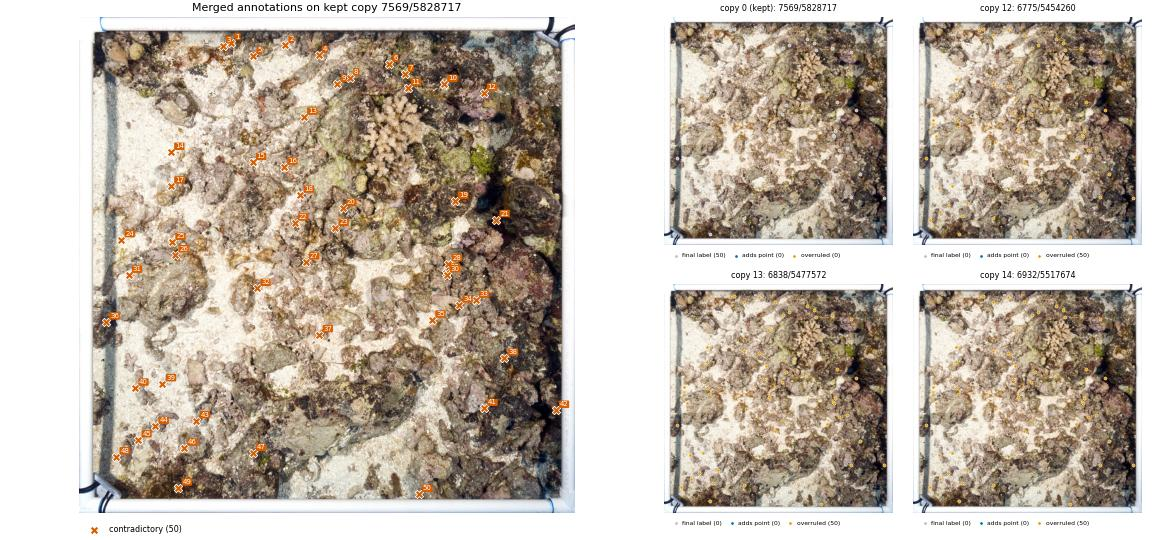

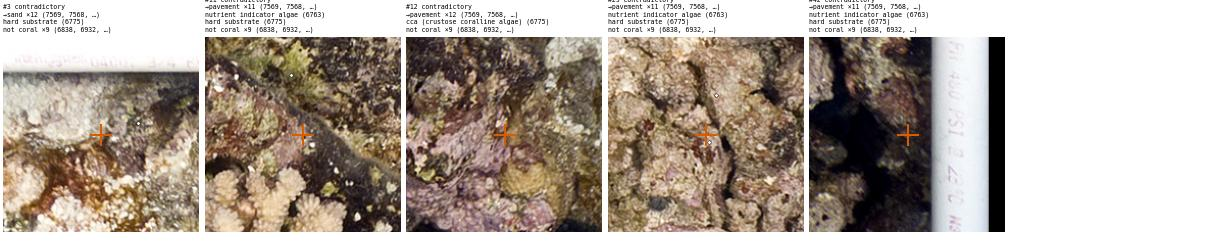

,status,row,col,final_label,from,kept_copy_label,labels_by_copy
nr,,,,,,,
3,contradictory,117,592,sand,7569/5828717,sand,"→sand ×12 (7569, 7568, 6924, 6855, …) | hard substrate (6775) | not coral ×9 (6838, 6932, 6931, 6868, …)"
11,contradictory,293,1356,pavement,7569/5828717,pavement,"→pavement ×11 (7569, 7568, 6924, 6855, …) | nutrient indicator algae (6763) | hard substrate (6775) | not …"
12,contradictory,313,1670,pavement,7569/5828717,pavement,"→pavement ×12 (7569, 7568, 6924, 6855, …) | cca (crustose coralline algae) (6775) | not coral ×9 (6838, …"
29,contradictory,1057,1515,pavement,7569/5828717,pavement,"→pavement ×11 (7569, 7568, 6924, 6855, …) | nutrient indicator algae (6763) | hard substrate (6775) | not …"
42,contradictory,1624,1968,pavement,7569/5828717,pavement,"→pavement ×11 (7569, 7568, 6924, 6855, …) | nutrient indicator algae (6763) | hard substrate (6775) | not …"
1,contradictory,105,628,pavement,7569/5828717,pavement,"→pavement ×11 (7569, 7568, 6924, 6855, …) | nutrient indicator algae (6763) | hard substrate (6775) | not …"
2,contradictory,116,850,sand,7569/5828717,sand,"→sand ×12 (7569, 7568, 6924, 6855, …) | hard substrate (6775) | not coral ×9 (6838, 6932, 6931, 6868, …)"
4,contradictory,157,988,pavement,7569/5828717,pavement,"→pavement ×11 (7569, 7568, 6924, 6855, …) | nutrient indicator algae (6763) | hard substrate (6775) | not …"
5,contradictory,162,718,sand,7569/5828717,sand,"→sand ×12 (7569, 7568, 6924, 6855, …) | hard substrate (6775) | not coral ×9 (6838, 6932, 6931, 6868, …)"


… 35 more points: r.show('6713fa8ca43f88dcc2de434cad97ce55', max_rows=None) for all
===== sources [7104]


---
### Image `e4e991e87fed`
**Kept copy: 7104/5622098** (BYS New Classifier; new split: train), one of 3 byte-identical copies in 3 source(s).
Why this copy: best-ranked source in conflict cluster 8 (rank 1 vs 7027's rank 3).
Merged result: 75 points (75 from the kept copy, 0 added from other copies).
- **contradictory** (55): labels clash; best-ranked copy's label used — **check these**
- **replaced: unmapped label** (19): kept copy's label not in class_to_concepts.csv; another copy's label used
Annotations for this image are **overridden** in the dataset.

,kept,source,image_id,name,new_split,cluster,source_rank,n_points,points_at_merged_locs
copy,,,,,,,,,
0,True,7104,5622098,BYS New Classifier,train,8,1,75,75
1,False,7027,5582982,(private/deleted),train,8,3,75,75
2,False,6695,5422217,(private/deleted),train,8,4,75,75


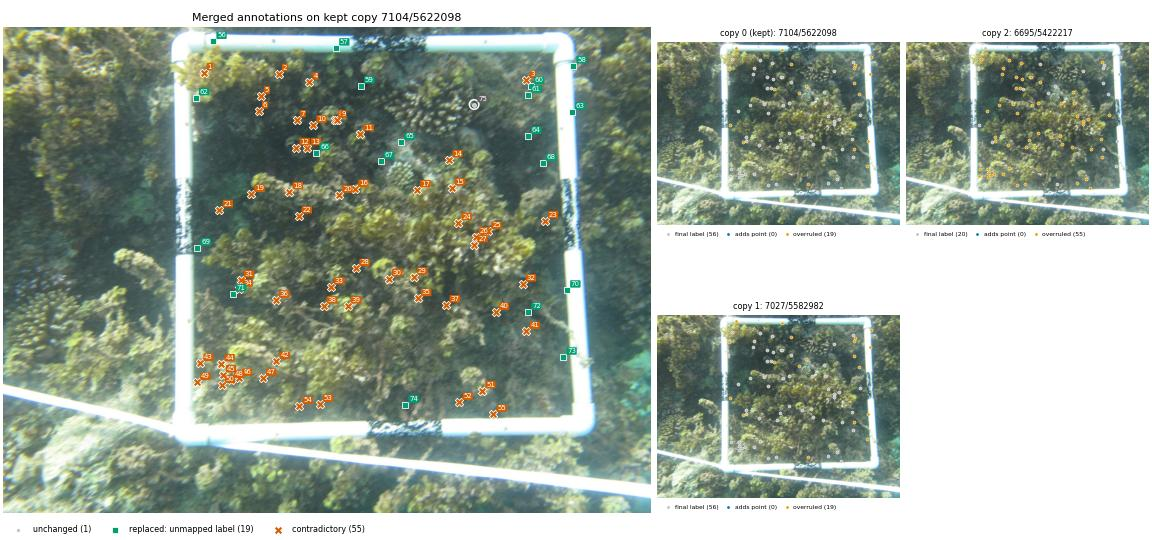

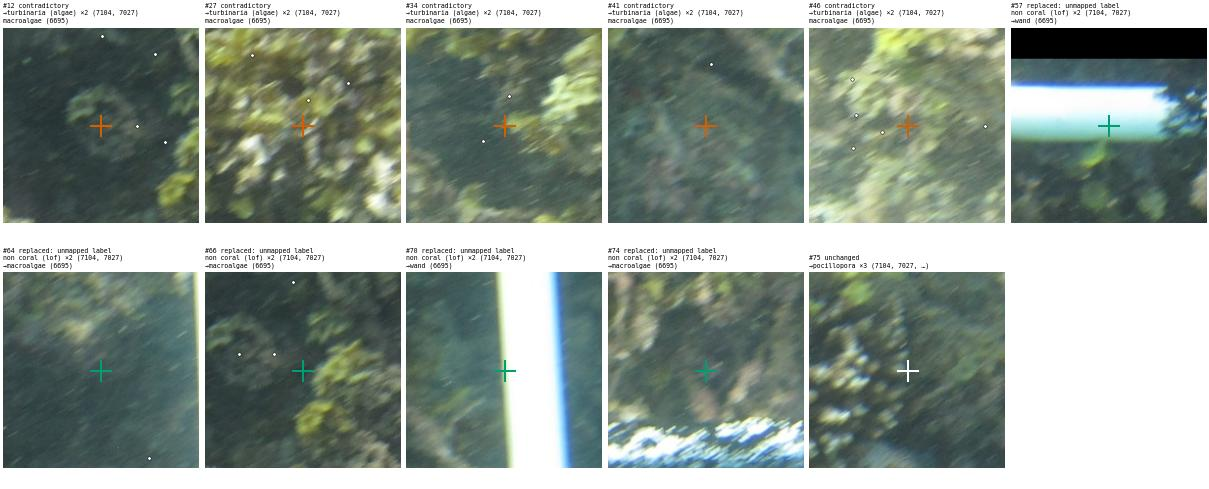

,status,row,col,final_label,from,kept_copy_label,labels_by_copy
nr,,,,,,,
12,contradictory,380,926,turbinaria (algae),7104/5622098,turbinaria (algae),"→turbinaria (algae) ×2 (7104, 7027) | macroalgae (6695)"
27,contradictory,687,1488,turbinaria (algae),7104/5622098,turbinaria (algae),"→turbinaria (algae) ×2 (7104, 7027) | macroalgae (6695)"
34,contradictory,827,746,turbinaria (algae),7104/5622098,turbinaria (algae),"→turbinaria (algae) ×2 (7104, 7027) | macroalgae (6695)"
41,contradictory,961,1653,turbinaria (algae),7104/5622098,turbinaria (algae),"→turbinaria (algae) ×2 (7104, 7027) | macroalgae (6695)"
46,contradictory,1109,744,turbinaria (algae),7104/5622098,turbinaria (algae),"→turbinaria (algae) ×2 (7104, 7027) | macroalgae (6695)"
57,replaced: unmapped label,65,1051,wand,6695/5422217,non coral (lof),"non coral (lof) ×2 (7104, 7027) | →wand (6695)"
64,replaced: unmapped label,344,1658,macroalgae,6695/5422217,non coral (lof),"non coral (lof) ×2 (7104, 7027) | →macroalgae (6695)"
66,replaced: unmapped label,396,989,macroalgae,6695/5422217,non coral (lof),"non coral (lof) ×2 (7104, 7027) | →macroalgae (6695)"
70,replaced: unmapped label,830,1781,wand,6695/5422217,non coral (lof),"non coral (lof) ×2 (7104, 7027) | →wand (6695)"


… 60 more points: r.show('e4e991e87fedd03173ace99c3296d783', max_rows=None) for all
===== sources [6543]


---
### Image `5fe5dd022ccf`
**Kept copy: 6543/5296828** (CYCLE ARMS-2; new split: train), one of 2 byte-identical copies in 2 source(s).
Why this copy: best-ranked source in conflict cluster 17 (rank 1 vs 4229's rank 2).
Merged result: 225 points (225 from the kept copy, 0 added from other copies).
- **contradictory** (44): labels clash; best-ranked copy's label used — **check these**
- **replaced: compatible** (1): labels don't clash but none covers the other; label with most taxonomic ranks used
- **replaced: finer** (1): kept copy's label replaced by a finer, consistent label
- **replaced: unmapped label** (4): kept copy's label not in class_to_concepts.csv; another copy's label used
- **kept over alternative** (3): kept copy's label stayed; another copy had a coarser/synonym/unmapped label
Annotations for this image are **overridden** in the dataset.

,kept,source,image_id,name,new_split,cluster,source_rank,n_points,points_at_merged_locs
copy,,,,,,,,,
0,True,6543,5296828,CYCLE ARMS-2,train,17,1,225,225
1,False,4229,3930404,CYCLE_ARMS,train,17,2,225,225


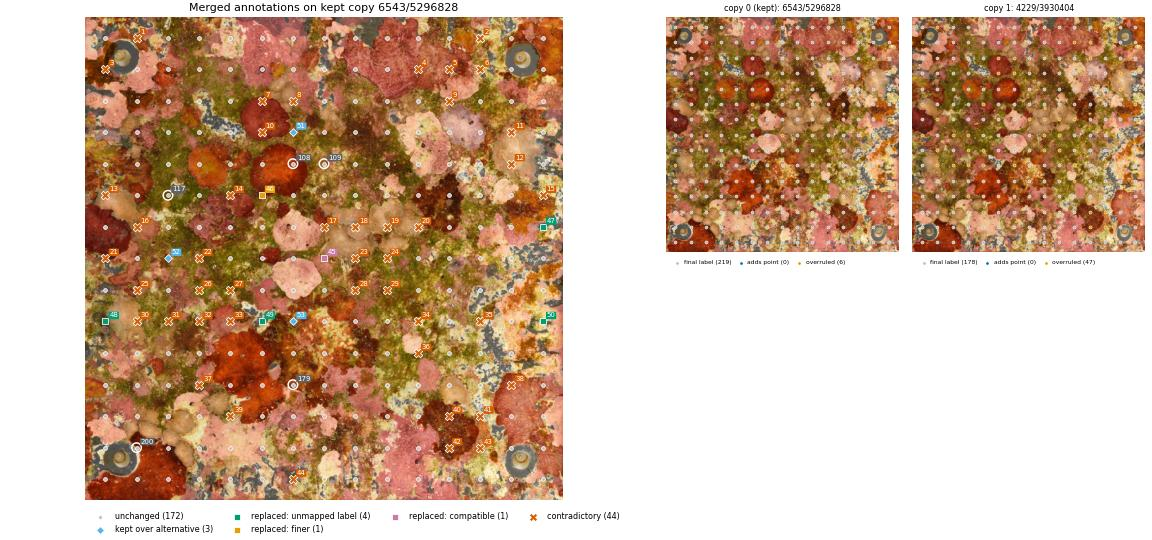

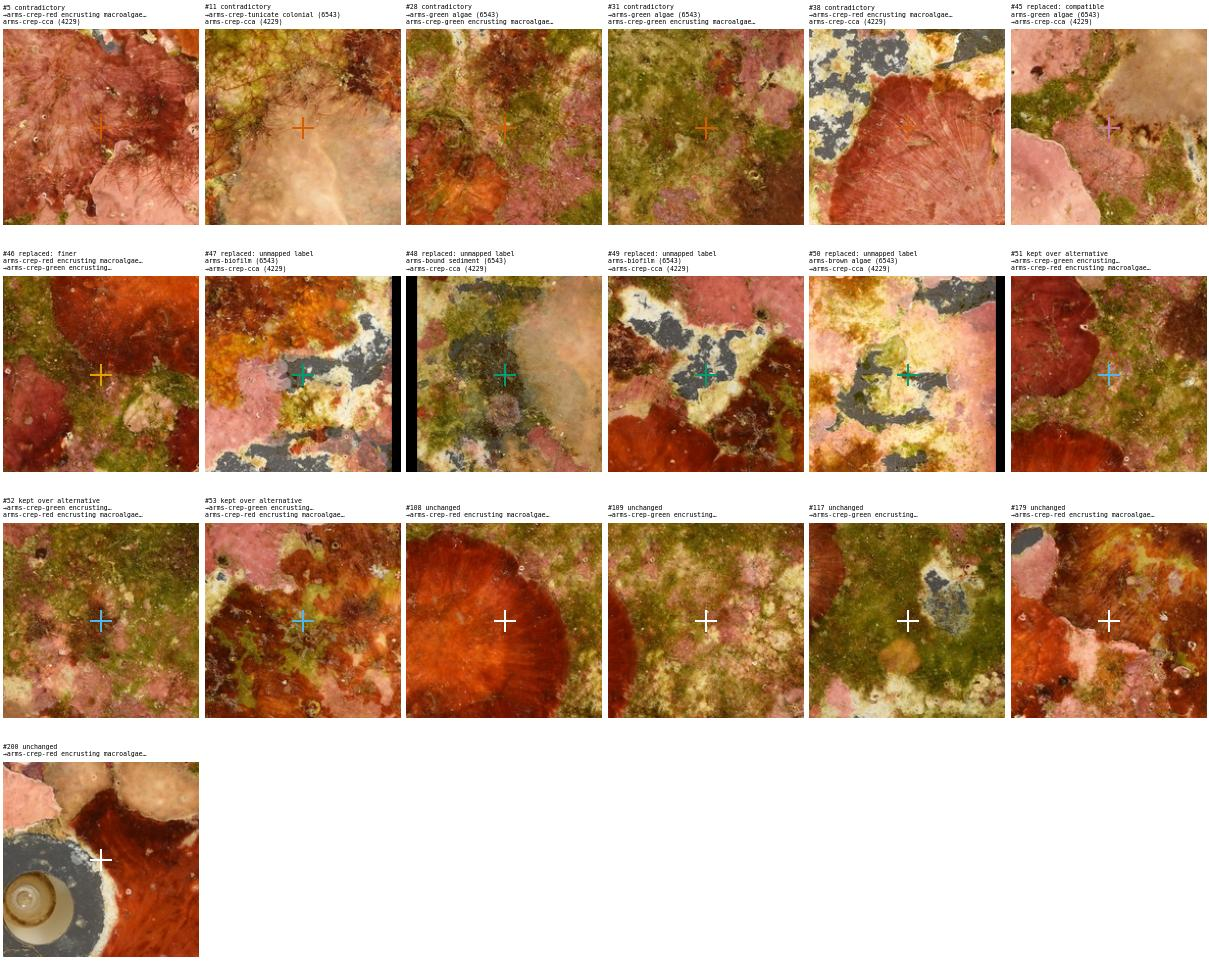

,status,row,col,final_label,from,kept_copy_label,labels_by_copy
nr,,,,,,,
5,contradictory,220,1541,arms-crep-red encrusting macroalgae,6543/5296828,arms-crep-red encrusting macroalgae,→arms-crep-red encrusting macroalgae (6543) | arms-crep-cca (4229)
11,contradictory,487,1806,arms-crep-tunicate colonial,6543/5296828,arms-crep-tunicate colonial,→arms-crep-tunicate colonial (6543) | arms-crep-cca (4229)
28,contradictory,1156,1144,arms-green algae,6543/5296828,arms-green algae,→arms-green algae (6543) | arms-crep-green encrusting macroalgae (4229)
31,contradictory,1290,350,arms-green algae,6543/5296828,arms-green algae,→arms-green algae (6543) | arms-crep-green encrusting macroalgae (4229)
38,contradictory,1558,1806,arms-crep-red encrusting macroalgae,6543/5296828,arms-crep-red encrusting macroalgae,→arms-crep-red encrusting macroalgae (6543) | arms-crep-cca (4229)
45,replaced: compatible,1022,1012,arms-crep-cca,4229/3930404,arms-green algae,arms-green algae (6543) | →arms-crep-cca (4229)
46,replaced: finer,755,747,arms-crep-green encrusting macroalgae,4229/3930404,arms-crep-red encrusting macroalgae,arms-crep-red encrusting macroalgae (6543) | →arms-crep-green encrusting macroalgae (4229)
47,replaced: unmapped label,889,1939,arms-crep-cca,4229/3930404,arms-biofilm,arms-biofilm (6543) | →arms-crep-cca (4229)
48,replaced: unmapped label,1290,85,arms-crep-cca,4229/3930404,arms-bound sediment,arms-bound sediment (6543) | →arms-crep-cca (4229)


… 43 more points: r.show('5fe5dd022ccf9e12acc87a71e6fc0a7e', max_rows=None) for all
===== sources [6956]


---
### Image `be0410d3c901`
**Kept copy: 6956/5544264** (REEFO_Test02; new split: train), one of 2 byte-identical copies in 2 source(s).
Why this copy: best-ranked source in conflict cluster 15 (rank 1 vs 6951's rank 2).
Merged result: 50 points (50 from the kept copy, 0 added from other copies).
- **contradictory** (37): labels clash; best-ranked copy's label used — **check these**
Annotations for this image are unchanged in the dataset (the kept copy's own points are used).

,kept,source,image_id,name,new_split,cluster,source_rank,n_points,points_at_merged_locs
copy,,,,,,,,,
0,True,6956,5544264,REEFO_Test02,train,15,1,50,50
1,False,6951,5538473,REEFO_Test01,train,15,2,50,50


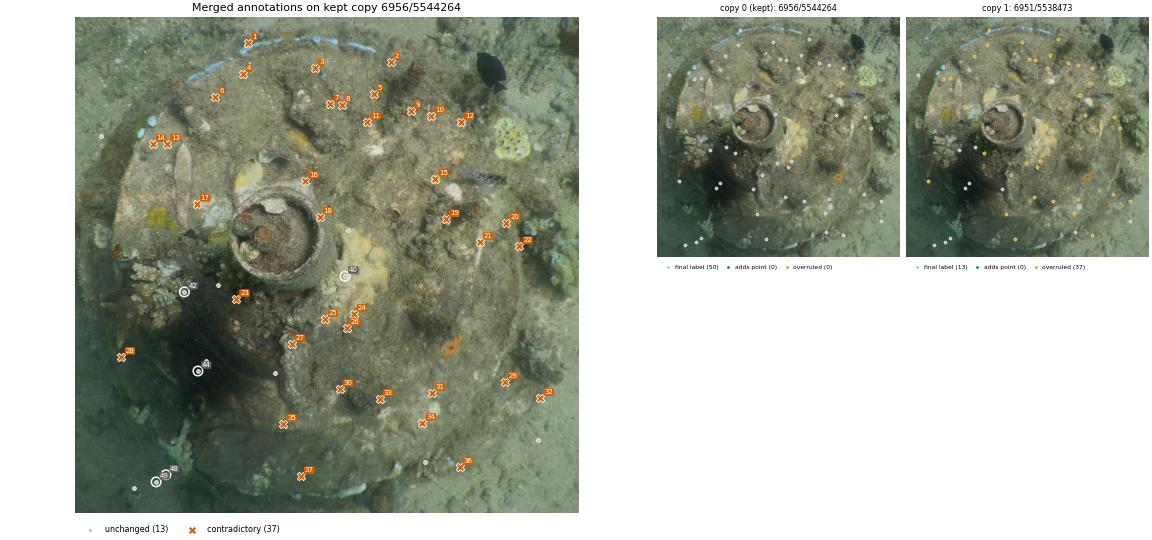

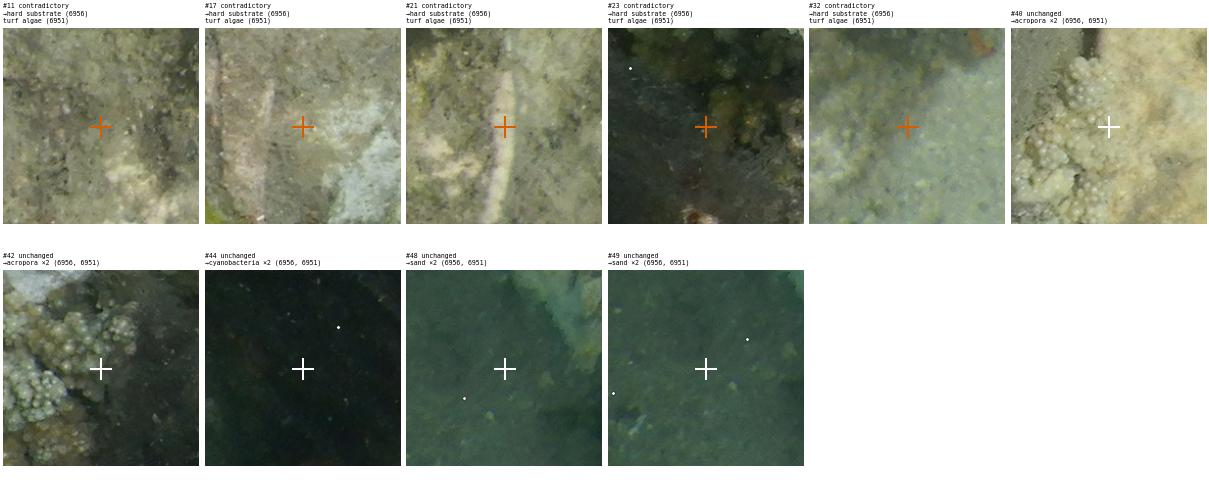

,status,row,col,final_label,from,kept_copy_label,labels_by_copy
nr,,,,,,,
11,contradictory,425,1187,hard substrate,6956/5544264,hard substrate,→hard substrate (6956) | turf algae (6951)
17,contradictory,759,493,hard substrate,6956/5544264,hard substrate,→hard substrate (6956) | turf algae (6951)
21,contradictory,914,1645,hard substrate,6956/5544264,hard substrate,→hard substrate (6956) | turf algae (6951)
23,contradictory,1146,653,hard substrate,6956/5544264,hard substrate,→hard substrate (6956) | turf algae (6951)
32,contradictory,1549,1891,hard substrate,6956/5544264,hard substrate,→hard substrate (6956) | turf algae (6951)
40,unchanged,1053,1096,acropora,6956/5544264,acropora,"→acropora ×2 (6956, 6951)"
42,unchanged,1117,443,acropora,6956/5544264,acropora,"→acropora ×2 (6956, 6951)"
44,unchanged,1439,498,cyanobacteria,6956/5544264,cyanobacteria,"→cyanobacteria ×2 (6956, 6951)"
48,unchanged,1861,368,sand,6956/5544264,sand,"→sand ×2 (6956, 6951)"


… 27 more points: r.show('be0410d3c9016aca6c78a0041cce350b', max_rows=None) for all
===== sources [2048, 1895]


---
### Image `ecbb01de0d51`
**Kept copy: 2048/1775866** (MBON_AR_CO_EC_US_Robot; new split: train), one of 9 byte-identical copies in 6 source(s).
Why this copy: best-ranked source in conflict cluster 4 (rank 2 vs 2562's rank 3).
Merged result: 200 points (100 from the kept copy, 23 added from other copies).
- **contradictory** (142): labels clash; best-ranked copy's label used — **check these**
- **added** (23): points only another copy had, added as is
- **kept over alternative** (5): kept copy's label stayed; another copy had a coarser/synonym/unmapped label
Annotations for this image are **overridden** in the dataset.

,kept,source,image_id,name,new_split,cluster,source_rank,n_points,points_at_merged_locs
copy,,,,,,,,,
0,True,2048,1775866,MBON_AR_CO_EC_US_Robot,train,4,2,100,100
1,False,2562,2032612,MBON_Robot Training,train,4,3,100,100
2,False,1983,1732478,MBON_Colombia,train,4,5,100,100
3,False,1972,1720924,MBON_AR_CO_EC,train,4,6,100,100
4,False,1972,1756970,MBON_AR_CO_EC,train,4,6,100,100
5,False,1972,1763287,MBON_AR_CO_EC,train,4,6,100,100


… 3 more copies (max_copies=None to show all)


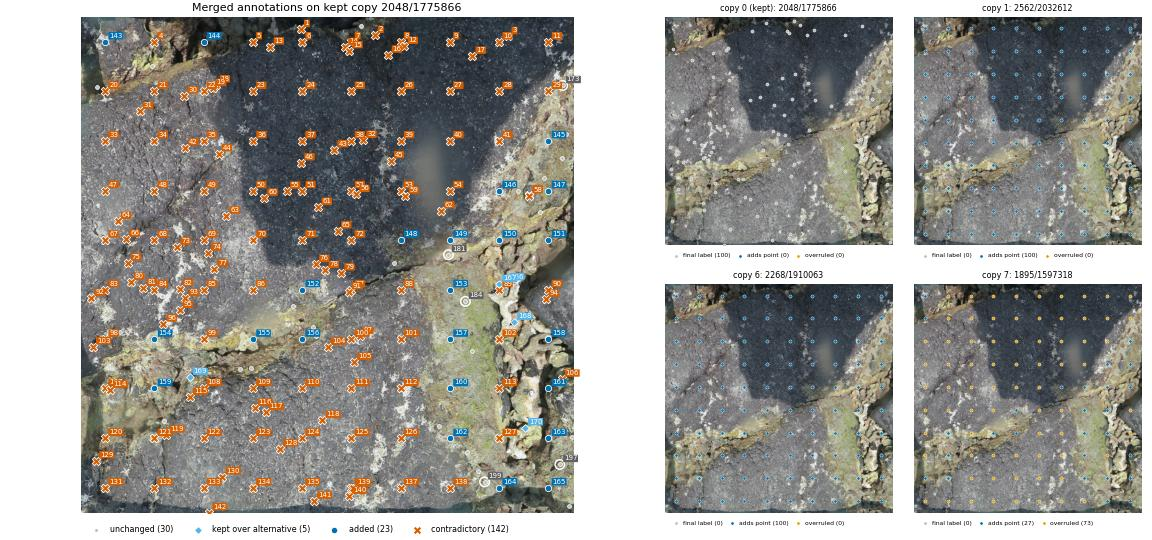

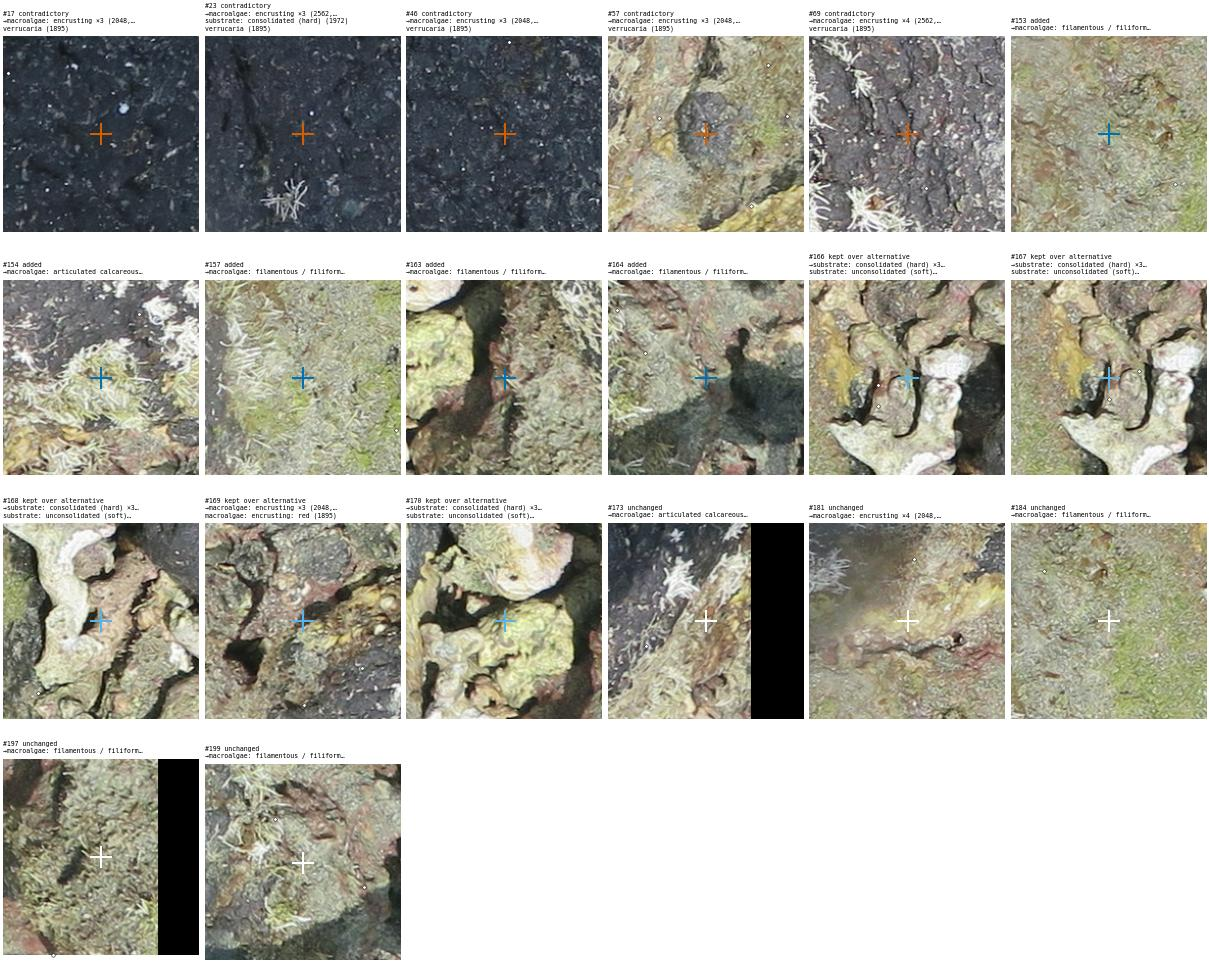

,status,row,col,final_label,from,kept_copy_label,labels_by_copy
nr,,,,,,,
17,contradictory,161,1617,macroalgae: encrusting,2048/1775866,macroalgae: encrusting,"→macroalgae: encrusting ×3 (2048, 1983, 1972) | verrucaria (1895)"
23,contradictory,306,711,macroalgae: encrusting,2562/2032612,—,"→macroalgae: encrusting ×3 (2562, 1972, 2268) | substrate: consolidated (hard) (1972) | verrucaria (1895)"
46,contradictory,601,910,macroalgae: encrusting,2048/1775866,macroalgae: encrusting,"→macroalgae: encrusting ×3 (2048, 1983, 1972) | verrucaria (1895)"
57,contradictory,734,1853,macroalgae: encrusting,2048/1775866,macroalgae: encrusting,"→macroalgae: encrusting ×3 (2048, 1983, 1972) | verrucaria (1895)"
69,contradictory,920,507,macroalgae: encrusting,2562/2032612,—,"→macroalgae: encrusting ×4 (2562, 1972, 2268) | verrucaria (1895)"
153,added,1125,1525,macroalgae: filamentous / filiform,2562/2032612,—,"→macroalgae: filamentous / filiform ×5 (2562, 1972, 2268, 1895)"
154,added,1330,304,macroalgae: articulated calcareous,2562/2032612,—,"→macroalgae: articulated calcareous ×5 (2562, 1972, 2268, 1895)"
157,added,1330,1525,macroalgae: filamentous / filiform,2562/2032612,—,"→macroalgae: filamentous / filiform ×5 (2562, 1972, 2268, 1895)"
163,added,1740,1932,macroalgae: filamentous / filiform,2562/2032612,—,"→macroalgae: filamentous / filiform ×5 (2562, 1972, 2268, 1895)"


… 160 more points: r.show('ecbb01de0d516f50ca4f722be5b38be3', max_rows=None) for all


In [10]:
for srcs in ([4710, 4721], [7569], [7104], [6543], [6956], [2048, 1895]):
    print(f"===== sources {srcs}")
    sel = r.select(["contradictory", "replaced: compatible"], sources=srcs, order="most", n=1)
    r.show_many(sel)

## 8. Duplicates in the new val / test splits

Val and test only use sources that share no image with another source, so any duplicate there is a copy within one source.
Their merged annotations are what gets evaluated, so they're worth a look.

val: 1,756 duplicated images, 1,756 with changed points
test: 805 duplicated images, 805 with changed points


---
### Image `cce92fb02550`
**Kept copy: 4759/4000478** (KAHO_Overlap_Plot; new split: val), one of 4 byte-identical copies in 1 source(s).
Why this copy: duplicate within one source: kept the copy with more points / lower image id.
Merged result: 4000 points (1000 from the kept copy, 3000 added from other copies).
- **added** (3000): points only another copy had, added as is
Annotations for this image are **overridden** in the dataset.

,kept,source,image_id,name,new_split,cluster,source_rank,n_points,points_at_merged_locs
copy,,,,,,,,,
0,True,4759,4000478,KAHO_Overlap_Plot,val,<NA>,<NA>,1000,1000
1,False,4759,4000753,KAHO_Overlap_Plot,val,<NA>,<NA>,1000,1000
2,False,4759,4000762,KAHO_Overlap_Plot,val,<NA>,<NA>,1000,1000
3,False,4759,4000767,KAHO_Overlap_Plot,val,<NA>,<NA>,1000,1000


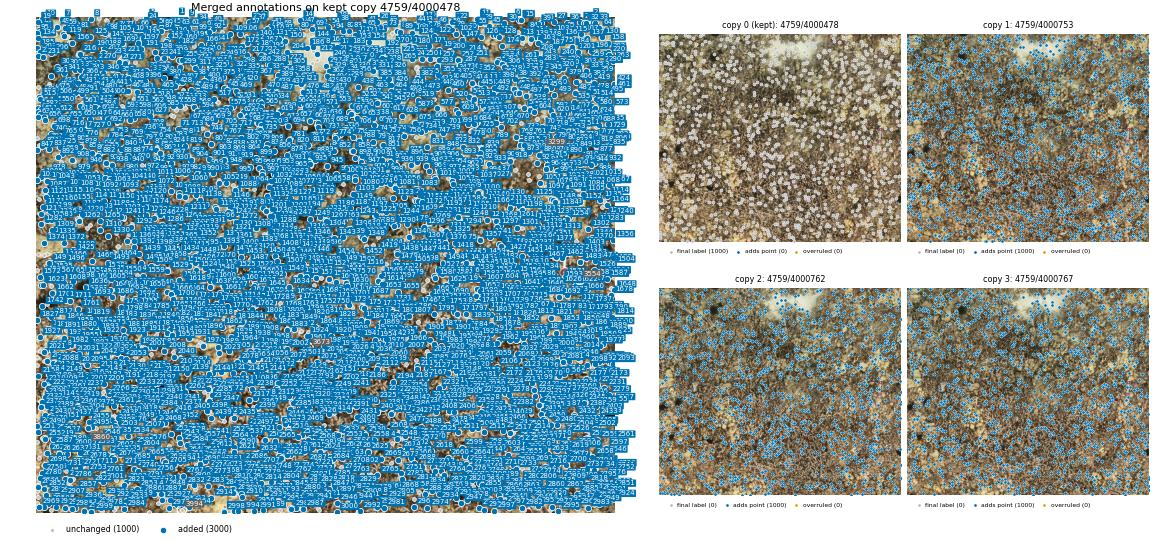

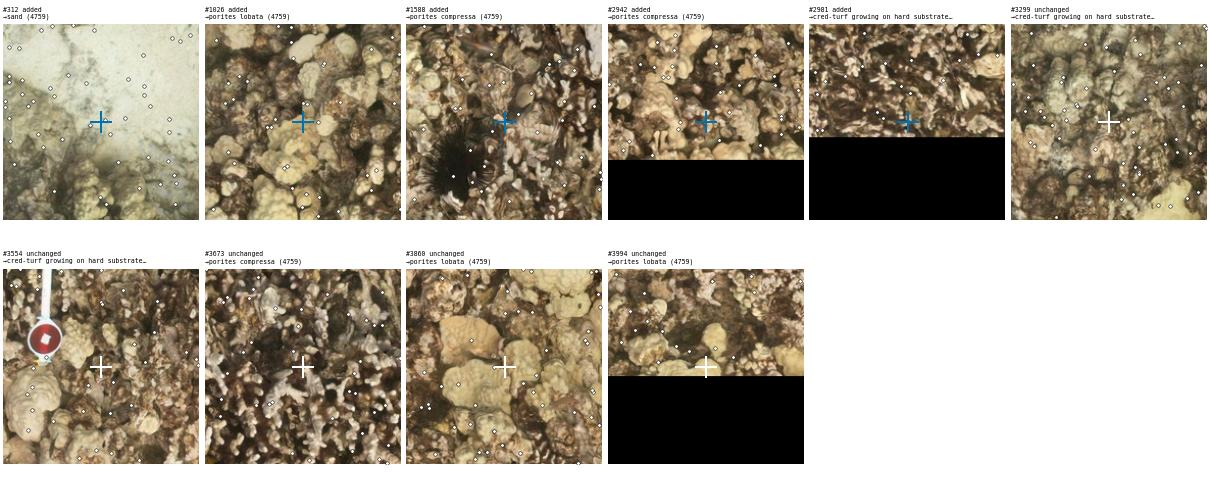

,status,row,col,final_label,from,kept_copy_label,labels_by_copy
nr,,,,,,,
312,added,180,1183,sand,4759/4000762,—,→sand (4759)
1026,added,576,1584,porites lobata,4759/4000753,—,→porites lobata (4759)
1588,added,929,208,porites compressa,4759/4000762,—,→porites compressa (4759)
2942,added,1718,1901,porites compressa,4759/4000753,—,→porites compressa (4759)
2981,added,1740,1229,cred-turf growing on hard substrate,4759/4000753,—,→cred-turf growing on hard substrate (4759)
3299,unchanged,463,1794,cred-turf growing on hard substrate,4759/4000478,cred-turf growing on hard substrate,→cred-turf growing on hard substrate (4759)
3554,unchanged,930,1924,cred-turf growing on hard substrate,4759/4000478,cred-turf growing on hard substrate,→cred-turf growing on hard substrate (4759)
3673,unchanged,1171,963,porites compressa,4759/4000478,porites compressa,→porites compressa (4759)
3860,unchanged,1508,182,porites lobata,4759/4000478,porites lobata,→porites lobata (4759)


… 2990 more points: r.show('cce92fb02550e1bc3262d832c38eeb3e', max_rows=None) for all


---
### Image `f2e9d2518327`
**Kept copy: 4759/4000476** (KAHO_Overlap_Plot; new split: val), one of 4 byte-identical copies in 1 source(s).
Why this copy: duplicate within one source: kept the copy with more points / lower image id.
Merged result: 3999 points (1000 from the kept copy, 2999 added from other copies).
- **contradictory** (1): labels clash; best-ranked copy's label used — **check these**
- **added** (2999): points only another copy had, added as is
Annotations for this image are **overridden** in the dataset.

,kept,source,image_id,name,new_split,cluster,source_rank,n_points,points_at_merged_locs
copy,,,,,,,,,
0,True,4759,4000476,KAHO_Overlap_Plot,val,<NA>,<NA>,1000,1000
1,False,4759,4000661,KAHO_Overlap_Plot,val,<NA>,<NA>,1000,1000
2,False,4759,4000662,KAHO_Overlap_Plot,val,<NA>,<NA>,1000,1000
3,False,4759,4000663,KAHO_Overlap_Plot,val,<NA>,<NA>,1000,1000


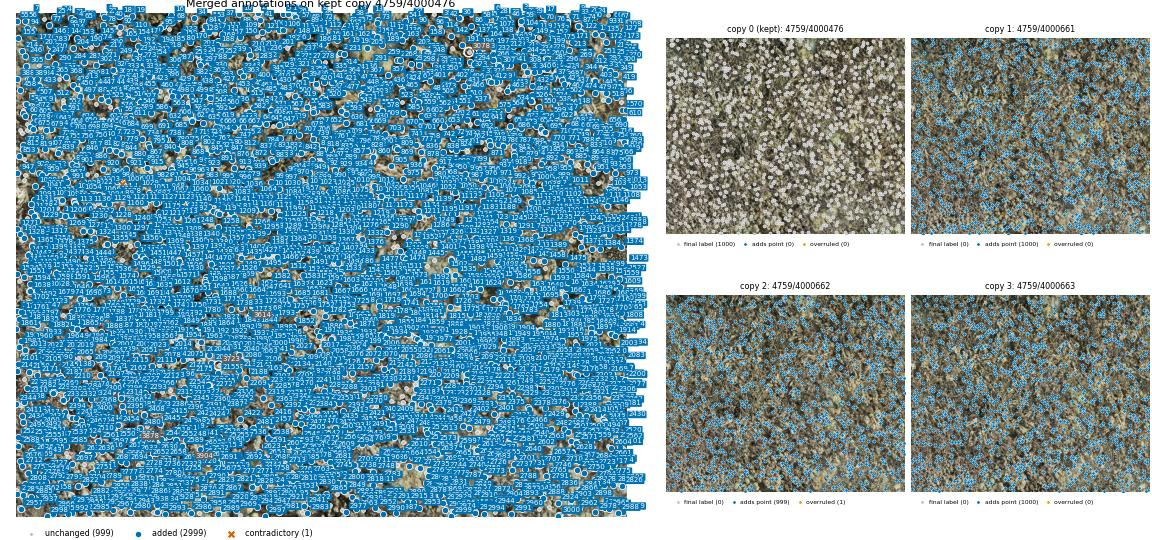

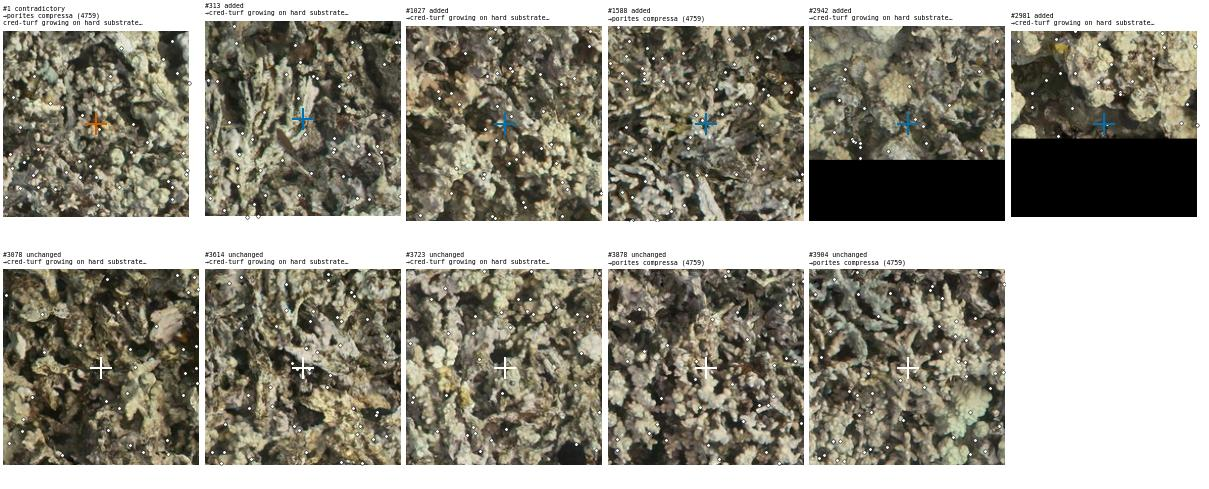

,status,row,col,final_label,from,kept_copy_label,labels_by_copy
nr,,,,,,,
1,contradictory,572,355,porites compressa,4759/4000476,porites compressa,→porites compressa (4759) | cred-turf growing on hard substrate (4759)
313,added,182,418,cred-turf growing on hard substrate,4759/4000663,—,→cred-turf growing on hard substrate (4759)
1027,added,589,1776,cred-turf growing on hard substrate,4759/4000662,—,→cred-turf growing on hard substrate (4759)
1588,added,905,125,porites compressa,4759/4000663,—,→porites compressa (4759)
2942,added,1653,1588,cred-turf growing on hard substrate,4759/4000663,—,→cred-turf growing on hard substrate (4759)
2981,added,1674,882,cred-turf growing on hard substrate,4759/4000663,—,→cred-turf growing on hard substrate (4759)
3078,unchanged,130,1519,cred-turf growing on hard substrate,4759/4000476,cred-turf growing on hard substrate,→cred-turf growing on hard substrate (4759)
3614,unchanged,1031,782,cred-turf growing on hard substrate,4759/4000476,cred-turf growing on hard substrate,→cred-turf growing on hard substrate (4759)
3723,unchanged,1181,680,cred-turf growing on hard substrate,4759/4000476,cred-turf growing on hard substrate,→cred-turf growing on hard substrate (4759)


… 2990 more points: r.show('f2e9d2518327632103c8368901ddcad0', max_rows=None) for all


In [11]:
for split in ("val", "test"):
    sub = r.images[r.images["split"] == split]
    print(f"{split}: {len(sub):,} duplicated images, {int(sub['n_changed'].gt(0).sum()):,} with changed points")
r.show_many(r.select(split="val", order="most", n=2))

## 9. Look up specific images

Paste CoralNet image ids (any copy) or source ids.

---
### Image `000589493b01`
**Kept copy: 4721/4551150** (Thuwal Bleaching Conditions; new split: train), one of 2 byte-identical copies in 2 source(s).
Why this copy: best-ranked source in conflict cluster 7 (rank 1 vs 4710's rank 2).
Merged result: 50 points (50 from the kept copy, 0 added from other copies).
- **contradictory** (1): labels clash; best-ranked copy's label used — **check these**
Annotations for this image are unchanged in the dataset (the kept copy's own points are used).

,kept,source,image_id,name,new_split,cluster,source_rank,n_points,points_at_merged_locs
copy,,,,,,,,,
0,True,4721,4551150,Thuwal Bleaching Conditions,train,7,1,50,50
1,False,4710,4551147,Thuwal Bleaching Taxonomic,train,7,2,50,50


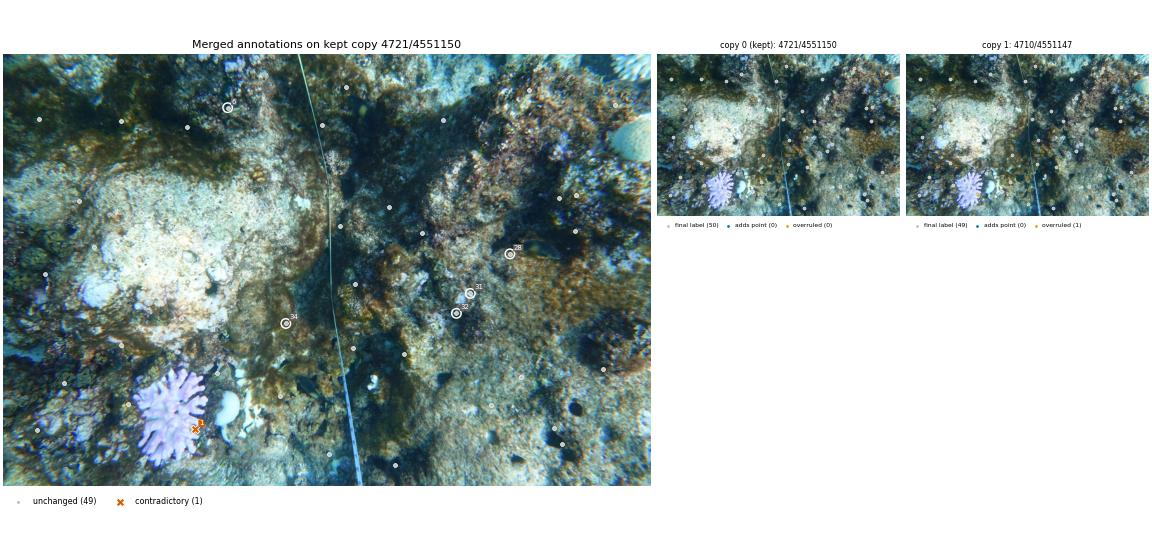

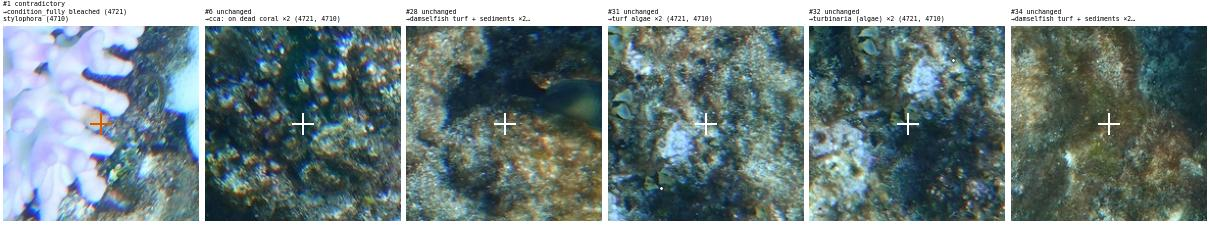

,status,row,col,final_label,from,kept_copy_label,labels_by_copy
nr,,,,,,,
1,contradictory,1185,606,condition_fully bleached,4721/4551150,condition_fully bleached,→condition_fully bleached (4721) | stylophora (4710)
6,unchanged,168,709,cca: on dead coral,4721/4551150,cca: on dead coral,"→cca: on dead coral ×2 (4721, 4710)"
28,unchanged,630,1601,damselfish turf + sediments,4721/4551150,damselfish turf + sediments,"→damselfish turf + sediments ×2 (4721, 4710)"
31,unchanged,755,1476,turf algae,4721/4551150,turf algae,"→turf algae ×2 (4721, 4710)"
32,unchanged,818,1432,turbinaria (algae),4721/4551150,turbinaria (algae),"→turbinaria (algae) ×2 (4721, 4710)"
34,unchanged,850,893,damselfish turf + sediments,4721/4551150,damselfish turf + sediments,"→damselfish turf + sediments ×2 (4721, 4710)"


In [12]:
r.show_many(r.select(image_ids=["4551150"]))